<a href="https://colab.research.google.com/github/aryanaroras/ARYAN-ARORA/blob/main/Phase123_23BDS0320.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Fall Semester 2026-27**

**Course Code: BCSE331L - Exploratory Data Analysis**

**Name: ARYAN ARORA**

**Registration Number: 23BDS0320**

**Phase 1 Date: 07 August 2026**

**Phase 2 Date: 24 September 2026**

**Phase 3 Date: 25 October 2026**

# **EDA on the Household Income Dataset**

## **1. Loading the Dataset**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

BLUE, RED, GOLD, GREEN, PURPLE, TEAL = "#2F4B7C", "#EF5B5B", "#FFA600", "#5B8C5A", "#8E6C88", "#3C9AB2"
PALETTE = [BLUE, RED, GOLD, GREEN, PURPLE, TEAL]
SEQ = sns.blend_palette(["#EDF2F7", BLUE], as_cmap=True)

sns.set_theme(style="whitegrid", palette=PALETTE)
plt.rcParams.update({"figure.dpi": 78, "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 9.5})

URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/income.csv"
income_raw = pd.read_csv(URL, keep_default_na=False, na_values=["NA"])

print("Rows:", income_raw.shape[0])
print("Columns:", income_raw.shape[1])
print("UNDER18 answered 'None' (no children):", (income_raw["UNDER18"] == "None").sum())
income_raw.head()

Rows: 8993
Columns: 14
UNDER18 answered 'None' (no children): 5724


,INCOME,SEX,MARITAL.STATUS,AGE,EDUCATION,OCCUPATION,AREA,DUAL.INCOMES,HOUSEHOLD.SIZE,UNDER18,HOUSEHOLDER,HOME.TYPE,ETHNIC.CLASS,LANGUAGE
0,[75.000-,F,Married,45-54,1 to 3 years of college,Homemaker,10+ years,No,Three,None,Own,House,White,NaN
1,[75.000-,M,Married,45-54,College graduate,Homemaker,10+ years,No,Five,Two,Own,House,White,English
2,[75.000-,F,Married,25-34,College graduate,Professional/Managerial,10+ years,Yes,Three,One,Rent,Apartment,White,English
3,-10.000),F,Single,14-17,Grades 9 to 11,"Student, HS or College",10+ years,Not Married,Four,Two,Family,House,White,English
4,-10.000),F,Single,14-17,Grades 9 to 11,"Student, HS or College",4-6 years,Not Married,Four,Two,Family,House,White,English


In [ ]:
df = income_raw.copy()
df.columns = [c.strip().replace(".", "_").upper() for c in df.columns]
df.columns.tolist()

['INCOME',
 'SEX',
 'MARITAL_STATUS',
 'AGE',
 'EDUCATION',
 'OCCUPATION',
 'AREA',
 'DUAL_INCOMES',
 'HOUSEHOLD_SIZE',
 'UNDER18',
 'HOUSEHOLDER',
 'HOME_TYPE',
 'ETHNIC_CLASS',
 'LANGUAGE']

## **2. Basic Statistical Analysis**

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8993 entries, 0 to 8992
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   INCOME          8993 non-null   str  
 1   SEX             8993 non-null   str  
 2   MARITAL_STATUS  8833 non-null   str  
 3   AGE             8993 non-null   str  
 4   EDUCATION       8907 non-null   str  
 5   OCCUPATION      8857 non-null   str  
 6   AREA            8080 non-null   str  
 7   DUAL_INCOMES    8993 non-null   str  
 8   HOUSEHOLD_SIZE  8618 non-null   str  
 9   UNDER18         8993 non-null   str  
 10  HOUSEHOLDER     8753 non-null   str  
 11  HOME_TYPE       8636 non-null   str  
 12  ETHNIC_CLASS    8925 non-null   str  
 13  LANGUAGE        8634 non-null   str  
dtypes: str(14)
memory usage: 983.7 KB


In [ ]:
df.describe(include="all").T

,count,unique,top,freq
INCOME,8993,9,-10.000),1745
SEX,8993,2,F,4918
MARITAL_STATUS,8833,5,Single,3654
AGE,8993,7,25-34,2249
EDUCATION,8907,6,1 to 3 years of college,3066
OCCUPATION,8857,9,Professional/Managerial,2820
AREA,8080,5,10+ years,5182
DUAL_INCOMES,8993,3,Not Married,5438
HOUSEHOLD_SIZE,8618,9,Two,2664
UNDER18,8993,10,None,5724


In [ ]:
overview = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
    "most_common": [df[c].mode().iat[0] for c in df.columns],
})
overview

,missing,missing_%,unique_values,most_common
INCOME,0,0.00,9,-10.000)
SEX,0,0.00,2,F
MARITAL_STATUS,160,1.78,5,Single
AGE,0,0.00,7,25-34
EDUCATION,86,0.96,6,1 to 3 years of college
OCCUPATION,136,1.51,9,Professional/Managerial
AREA,913,10.15,5,10+ years
DUAL_INCOMES,0,0.00,3,Not Married
HOUSEHOLD_SIZE,375,4.17,9,Two
UNDER18,0,0.00,10,None


In [ ]:
for col in ["INCOME", "EDUCATION", "OCCUPATION"]:
    print(col)
    print(df[col].value_counts().to_string())
    print()

INCOME
INCOME
-10.000)           1745
[50.000-75.000)    1308
[30.000-40.000)    1110
[40.000-50.000)     969
[75.000-            884
[20.000-25.000)     813
[10.000-15.000)     775
[25.000-30.000)     722
[15.000-20.000)     667

EDUCATION
EDUCATION
1 to 3 years of college    3066
Graduated High Scool       2041
College graduate           1524
Grades 9 to 11             1046
Grad Study                  966
Grade 8 or less             264

OCCUPATION
OCCUPATION
Professional/Managerial          2820
Student, HS or College           1489
Clerical/Service Worker          1062
Sales Worker                      770
Factory Worker/Laborer/Driver     767
Retired                           690
Homemaker                         650
Unemployed                        337
Military                          272



## **3. Handling Missing Data**

In [ ]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
})
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
missing

,missing,missing_%
AREA,913,10.15
HOUSEHOLD_SIZE,375,4.17
LANGUAGE,359,3.99
HOME_TYPE,357,3.97
HOUSEHOLDER,240,2.67
MARITAL_STATUS,160,1.78
OCCUPATION,136,1.51
EDUCATION,86,0.96
ETHNIC_CLASS,68,0.76


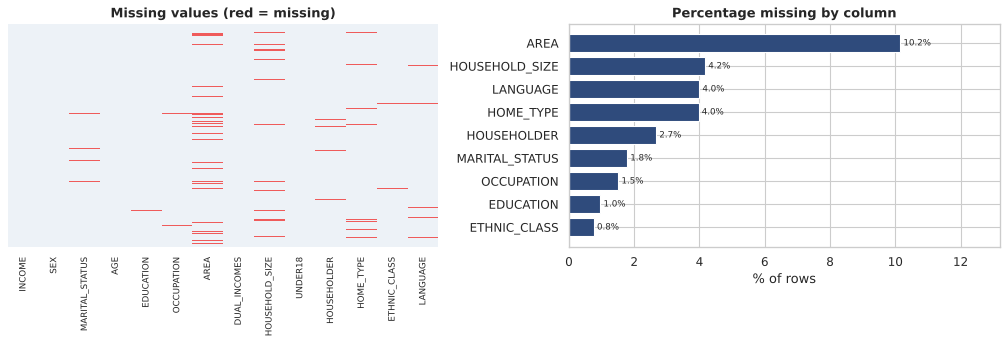

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.heatmap(df.isna(), cbar=False, cmap=ListedColormap(["#EDF2F7", RED]), yticklabels=False, ax=axes[0])
axes[0].set_title("Missing values (red = missing)")
axes[0].tick_params(axis="x", rotation=90, labelsize=8)

bars = axes[1].barh(missing.index[::-1], missing["missing_%"][::-1], color=BLUE)
axes[1].bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
axes[1].set_title("Percentage missing by column")
axes[1].set_xlabel("% of rows")
axes[1].set_xlim(0, missing["missing_%"].max() * 1.3)

plt.tight_layout()
plt.show()

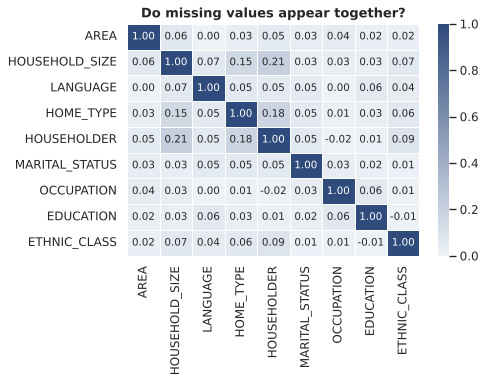

Rows with at least one missing value: 2117
Fully complete rows: 6876


In [ ]:
gaps = df[missing.index].isna().astype(int)

plt.figure(figsize=(6.5, 5))
sns.heatmap(gaps.corr(), annot=True, fmt=".2f", cmap=SEQ, vmin=0, vmax=1, linewidths=0.5, linecolor="white")
plt.title("Do missing values appear together?")
plt.tight_layout()
plt.show()

print("Rows with at least one missing value:", (df.isna().sum(axis=1) > 0).sum())
print("Fully complete rows:", (df.isna().sum(axis=1) == 0).sum())

In [ ]:
work = df.dropna(subset=["INCOME"]).reset_index(drop=True)

rates = work.isna().mean()
unknown_cols = [c for c in work.columns if rates[c] > 0.05]
mode_cols = [c for c in work.columns if 0 < rates[c] <= 0.05]

for c in unknown_cols:
    work[c] = work[c].fillna("Unknown")
for c in mode_cols:
    work[c] = work[c].fillna(work[c].mode().iat[0])

print("Filled with 'Unknown':", unknown_cols)
print("Filled with mode:", mode_cols)
print("Missing values left:", int(work.isna().sum().sum()))

Filled with 'Unknown': ['AREA']
Filled with mode: ['MARITAL_STATUS', 'EDUCATION', 'OCCUPATION', 'HOUSEHOLD_SIZE', 'HOUSEHOLDER', 'HOME_TYPE', 'ETHNIC_CLASS', 'LANGUAGE']
Missing values left: 0


## **4. Data Cleaning**

In [ ]:
for c in work.select_dtypes(include="object").columns:
    work[c] = work[c].astype(str).str.strip()

print("Before:")
print(work["EDUCATION"].value_counts().to_string())

work["EDUCATION"] = work["EDUCATION"].replace({"Graduated High Scool": "Graduated High School"})

print()
print("After fixing the spelling:")
print(work["EDUCATION"].value_counts().to_string())

Before:
EDUCATION
1 to 3 years of college    3152
Graduated High Scool       2041
College graduate           1524
Grades 9 to 11             1046
Grad Study                  966
Grade 8 or less             264

After fixing the spelling:
EDUCATION
1 to 3 years of college    3152
Graduated High School      2041
College graduate           1524
Grades 9 to 11             1046
Grad Study                  966
Grade 8 or less             264


In [ ]:
married = work["MARITAL_STATUS"] == "Married"
conflict = married & (work["DUAL_INCOMES"] == "Not Married")

print("Contradictory rows:", conflict.sum())
pd.crosstab(work["MARITAL_STATUS"], work["DUAL_INCOMES"])

Contradictory rows: 93


DUAL_INCOMES,No,Not Married,Yes
MARITAL_STATUS,,,
Divorced,0,875,0
Married,1219,93,2022
Single,45,3727,42
Together,80,441,147
Widowed,0,302,0


In [ ]:
work["DUAL_INCOMES_CLEAN"] = work["DUAL_INCOMES"].where(~conflict, "Unclear")
work["DUAL_INCOMES_CLEAN"].value_counts()

DUAL_INCOMES_CLEAN
Not Married    5345
Yes            2211
No             1344
Unclear          93
Name: count, dtype: int64

In [ ]:
teen = work["AGE"] == "14-17"
impossible = teen & (
    work["EDUCATION"].isin(["College graduate", "Grad Study"])
    | work["OCCUPATION"].isin(["Retired", "Military"])
    | work["MARITAL_STATUS"].isin(["Married", "Divorced", "Widowed"])
)

print("Impossible rows found:", impossible.sum())
print(work.loc[impossible, ["AGE", "EDUCATION", "OCCUPATION", "MARITAL_STATUS"]].head().to_string())

work = work.loc[~impossible].reset_index(drop=True)
print()
print("Rows kept:", len(work))

Impossible rows found: 23
        AGE              EDUCATION               OCCUPATION MARITAL_STATUS
54    14-17       College graduate                  Retired        Married
608   14-17         Grades 9 to 11                Homemaker        Married
801   14-17         Grades 9 to 11  Professional/Managerial        Married
1613  14-17  Graduated High School             Sales Worker       Divorced
1668  14-17  Graduated High School                 Military         Single

Rows kept: 8970


In [ ]:
print("Exact duplicate rows:", work.duplicated().sum())

Exact duplicate rows: 776


## **5. Data Transformation**

In [ ]:
income_order = ["-10.000)", "[10.000-15.000)", "[15.000-20.000)", "[20.000-25.000)", "[25.000-30.000)",
                "[30.000-40.000)", "[40.000-50.000)", "[50.000-75.000)", "[75.000-"]
income_label = dict(zip(income_order,
    ["< 10K", "10-15K", "15-20K", "20-25K", "25-30K", "30-40K", "40-50K", "50-75K", "75K +"]))
income_mid = dict(zip(income_order, [5, 12.5, 17.5, 22.5, 27.5, 35, 45, 62.5, 87.5]))

age_order = ["14-17", "18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
age_mid = dict(zip(age_order, [15.5, 21, 29.5, 39.5, 49.5, 59.5, 70]))

edu_order = ["Grade 8 or less", "Grades 9 to 11", "Graduated High School",
             "1 to 3 years of college", "College graduate", "Grad Study"]
edu_rank = {level: i + 1 for i, level in enumerate(edu_order)}

area_years = {"-1 year": 0.5, "1-3 years": 2, "4-6 years": 5, "7-10 years": 8.5, "10+ years": 12}

words = {"None": 0, "One": 1, "Two": 2, "Three": 3, "Four": 4,
         "Five": 5, "Six": 6, "Seven": 7, "Eight": 8, "Nine or more": 9}

tidy = work.copy()

tidy["INCOME_BAND"] = pd.Categorical(tidy["INCOME"].map(income_label),
                                     categories=[income_label[k] for k in income_order], ordered=True)
tidy["AGE_BAND"] = pd.Categorical(tidy["AGE"], categories=age_order, ordered=True)
tidy["EDU_BAND"] = pd.Categorical(tidy["EDUCATION"], categories=edu_order, ordered=True)

tidy["INCOME_K"] = tidy["INCOME"].map(income_mid)
tidy["AGE_YEARS"] = tidy["AGE"].map(age_mid)
tidy["EDU_RANK"] = tidy["EDUCATION"].map(edu_rank)
tidy["AREA_YEARS"] = tidy["AREA"].map(area_years)
tidy["HH_SIZE"] = tidy["HOUSEHOLD_SIZE"].map(words)
tidy["CHILDREN"] = tidy["UNDER18"].map(words)
tidy["OWNS_HOME"] = (tidy["HOUSEHOLDER"] == "Own").astype(int)

tidy.head(3)

,INCOME,SEX,MARITAL_STATUS,AGE,EDUCATION,OCCUPATION,AREA,DUAL_INCOMES,HOUSEHOLD_SIZE,UNDER18,...,INCOME_BAND,AGE_BAND,EDU_BAND,INCOME_K,AGE_YEARS,EDU_RANK,AREA_YEARS,HH_SIZE,CHILDREN,OWNS_HOME
0,[75.000-,F,Married,45-54,1 to 3 years of college,Homemaker,10+ years,No,Three,None,...,75K +,45-54,1 to 3 years of college,87.5,49.5,4,12.0,3,0,1
1,[75.000-,M,Married,45-54,College graduate,Homemaker,10+ years,No,Five,Two,...,75K +,45-54,College graduate,87.5,49.5,5,12.0,5,2,1
2,[75.000-,F,Married,25-34,College graduate,Professional/Managerial,10+ years,Yes,Three,One,...,75K +,25-34,College graduate,87.5,29.5,5,12.0,3,1,0


In [ ]:
numeric_cols = ["INCOME_K", "AGE_YEARS", "EDU_RANK", "AREA_YEARS", "HH_SIZE", "CHILDREN", "OWNS_HOME"]

print("Values that could not be mapped:")
print(tidy[numeric_cols].isna().sum().to_string())

tidy[numeric_cols].describe().T.round(2)

Values that could not be mapped:
INCOME_K        0
AGE_YEARS       0
EDU_RANK        0
AREA_YEARS    909
HH_SIZE         0
CHILDREN        0
OWNS_HOME       0


,count,mean,std,min,25%,50%,75%,max
INCOME_K,8970.0,34.49,25.52,5.0,12.5,27.5,45.0,87.5
AGE_YEARS,8970.0,34.67,15.32,15.5,21.0,29.5,39.5,70.0
EDU_RANK,8970.0,3.84,1.23,1.0,3.0,4.0,5.0,6.0
AREA_YEARS,8061.0,9.34,3.97,0.5,8.5,12.0,12.0,12.0
HH_SIZE,8970.0,2.81,1.51,1.0,2.0,2.0,4.0,9.0
CHILDREN,8970.0,0.66,1.08,0.0,0.0,0.0,1.0,9.0
OWNS_HOME,8970.0,0.36,0.48,0.0,0.0,0.0,1.0,1.0


In [ ]:
print("Median income:", tidy["INCOME_K"].median(), "K")
print("Mean income:", round(tidy["INCOME_K"].mean(), 2), "K")
print("Standard deviation:", round(tidy["INCOME_K"].std(), 2))
print("Skew:", round(tidy["INCOME_K"].skew(), 2))

Median income: 27.5 K
Mean income: 34.49 K
Standard deviation: 25.52
Skew: 0.7


## **6. Univariate Analysis**

### Plot 1 - Income distribution

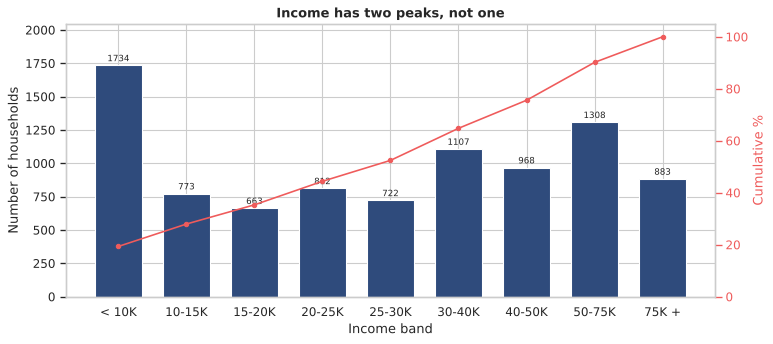

Households below 25K: 44.4 %
Households at 50K or above: 24.4 %


In [ ]:
counts = tidy["INCOME_BAND"].value_counts().sort_index()
cumulative = counts.cumsum() / counts.sum() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(counts.index.astype(str), counts.values, color=BLUE, width=0.68)
ax.bar_label(bars, padding=2, fontsize=8)
ax.set_title("Income has two peaks, not one")
ax.set_xlabel("Income band")
ax.set_ylabel("Number of households")
ax.set_ylim(0, counts.max() * 1.18)

twin = ax.twinx()
twin.plot(counts.index.astype(str), cumulative.values, color=RED, marker="o", markersize=4)
twin.set_ylabel("Cumulative %", color=RED)
twin.tick_params(axis="y", colors=RED)
twin.set_ylim(0, 105)
twin.grid(False)

plt.tight_layout()
plt.show()

print("Households below 25K:", round((tidy["INCOME_K"] < 25).mean() * 100, 1), "%")
print("Households at 50K or above:", round((tidy["INCOME_K"] >= 50).mean() * 100, 1), "%")

### Plot 2 - Age, education, occupation and home type

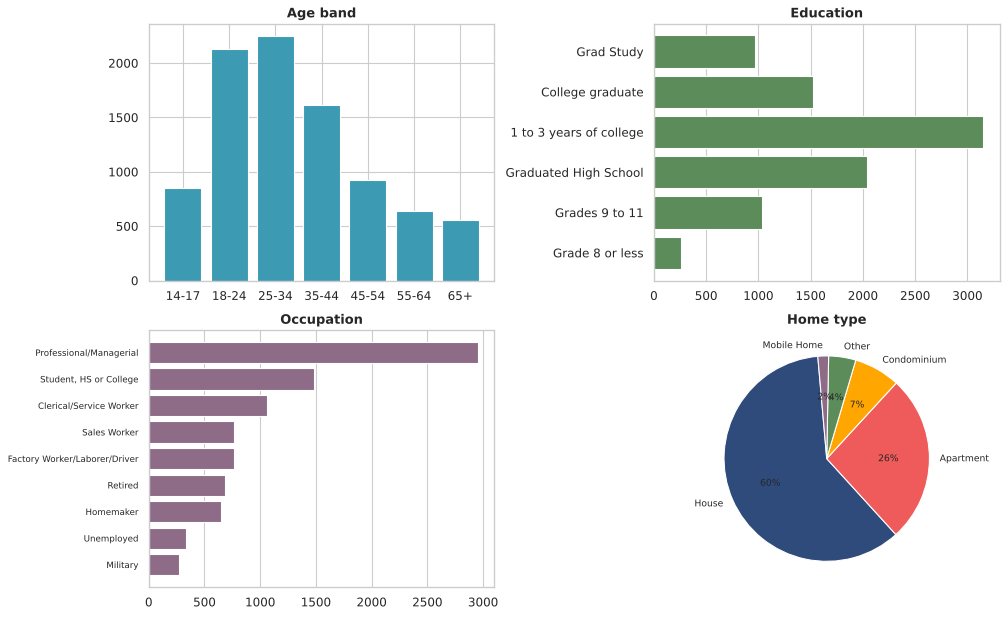

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

age_counts = tidy["AGE_BAND"].value_counts().sort_index()
axes[0, 0].bar(age_counts.index.astype(str), age_counts.values, color=TEAL)
axes[0, 0].set_title("Age band")

edu_counts = tidy["EDU_BAND"].value_counts().sort_index()
axes[0, 1].barh(edu_counts.index.astype(str), edu_counts.values, color=GREEN)
axes[0, 1].set_title("Education")
axes[0, 1].grid(axis="y", visible=False)

occ_counts = tidy["OCCUPATION"].value_counts().sort_values()
axes[1, 0].barh(occ_counts.index.astype(str), occ_counts.values, color=PURPLE)
axes[1, 0].set_title("Occupation")
axes[1, 0].grid(axis="y", visible=False)
axes[1, 0].tick_params(axis="y", labelsize=8)

home_counts = tidy["HOME_TYPE"].value_counts()
axes[1, 1].pie(home_counts.values, labels=home_counts.index.astype(str), autopct="%1.0f%%",
               colors=PALETTE, startangle=95, textprops={"fontsize": 8.5})
axes[1, 1].set_title("Home type")

plt.tight_layout()
plt.show()

### Plot 3 - Income and household size

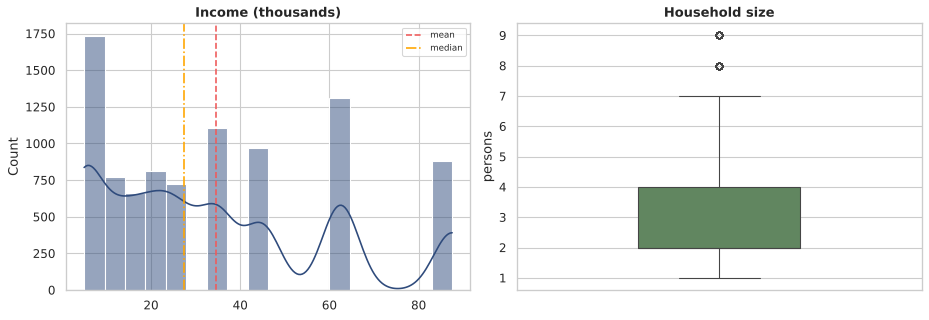

Most common household size: 2 persons


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

sns.histplot(tidy["INCOME_K"], bins=18, kde=True, color=BLUE, edgecolor="white", ax=axes[0])
axes[0].axvline(tidy["INCOME_K"].mean(), color=RED, linestyle="--", label="mean")
axes[0].axvline(tidy["INCOME_K"].median(), color=GOLD, linestyle="-.", label="median")
axes[0].set_title("Income (thousands)")
axes[0].set_xlabel("")
axes[0].legend(fontsize=8)

sns.boxplot(y=tidy["HH_SIZE"], color=GREEN, width=0.4, ax=axes[1])
axes[1].set_title("Household size")
axes[1].set_ylabel("persons")

plt.tight_layout()
plt.show()

print("Most common household size:", int(tidy["HH_SIZE"].mode().iat[0]), "persons")

## **7. Bivariate Analysis**

### Plot 4 - Income and education

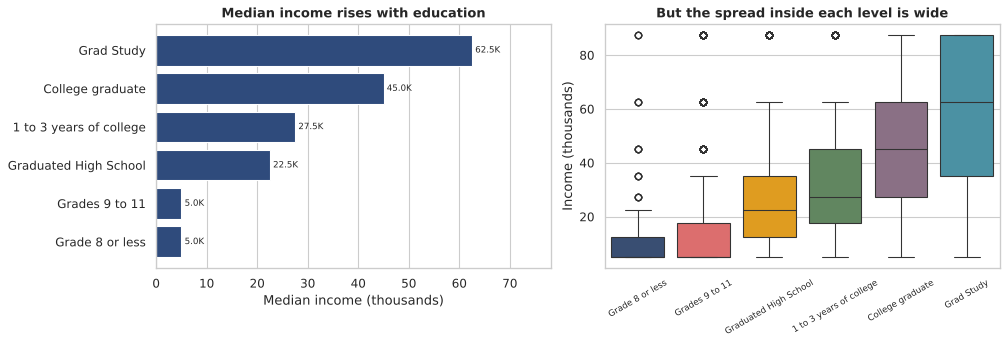

Spearman correlation between education rank and income: 0.452


In [ ]:
edu_median = tidy.groupby("EDU_BAND", observed=True)["INCOME_K"].median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bars = axes[0].barh(edu_median.index.astype(str), edu_median.values, color=BLUE)
axes[0].bar_label(bars, fmt="%.1fK", padding=3, fontsize=8)
axes[0].set_title("Median income rises with education")
axes[0].set_xlabel("Median income (thousands)")
axes[0].set_xlim(0, edu_median.max() * 1.25)
axes[0].grid(axis="y", visible=False)

sns.boxplot(data=tidy, x="EDU_BAND", y="INCOME_K", palette=PALETTE, ax=axes[1])
axes[1].set_title("But the spread inside each level is wide")
axes[1].set_xlabel("")
axes[1].set_ylabel("Income (thousands)")
axes[1].tick_params(axis="x", rotation=30, labelsize=8)

plt.tight_layout()
plt.show()

print("Spearman correlation between education rank and income:",
      round(tidy["EDU_RANK"].corr(tidy["INCOME_K"], method="spearman"), 3))

### Plot 5 - Income across age groups

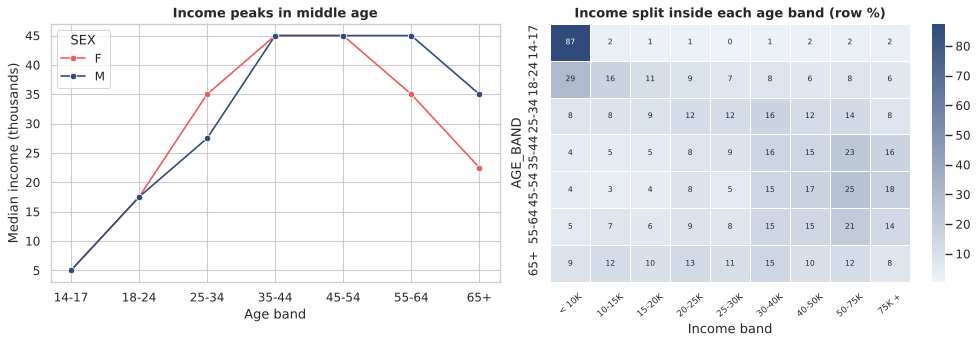

In [ ]:
life = tidy.groupby(["AGE_BAND", "SEX"], observed=True)["INCOME_K"].median().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.lineplot(data=life, x="AGE_BAND", y="INCOME_K", hue="SEX", marker="o", palette=[RED, BLUE], ax=axes[0])
axes[0].set_title("Income peaks in middle age")
axes[0].set_xlabel("Age band")
axes[0].set_ylabel("Median income (thousands)")

share = pd.crosstab(tidy["AGE_BAND"], tidy["INCOME_BAND"], normalize="index") * 100
sns.heatmap(share, cmap=SEQ, annot=True, fmt=".0f", linewidths=0.5, linecolor="white",
            annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Income split inside each age band (row %)")
axes[1].set_xlabel("Income band")
axes[1].tick_params(axis="x", rotation=40, labelsize=8)

plt.tight_layout()
plt.show()

### Plot 6 - Dual incomes and home ownership

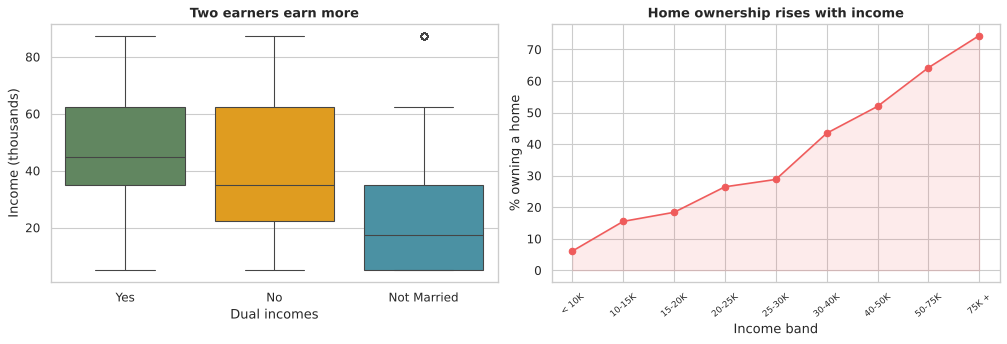

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

dual = tidy[tidy["DUAL_INCOMES_CLEAN"].isin(["Yes", "No", "Not Married"])]
sns.boxplot(data=dual, x="DUAL_INCOMES_CLEAN", y="INCOME_K", order=["Yes", "No", "Not Married"],
            palette=[GREEN, GOLD, TEAL], ax=axes[0])
axes[0].set_title("Two earners earn more")
axes[0].set_xlabel("Dual incomes")
axes[0].set_ylabel("Income (thousands)")

own = tidy.groupby("INCOME_BAND", observed=True)["OWNS_HOME"].mean().mul(100)
axes[1].plot(own.index.astype(str), own.values, color=RED, marker="o")
axes[1].fill_between(own.index.astype(str), own.values, color=RED, alpha=0.12)
axes[1].set_title("Home ownership rises with income")
axes[1].set_xlabel("Income band")
axes[1].set_ylabel("% owning a home")
axes[1].tick_params(axis="x", rotation=40, labelsize=8)

plt.tight_layout()
plt.show()

## **8. Multivariate Analysis**

### Plot 7 - Correlation between all numeric columns

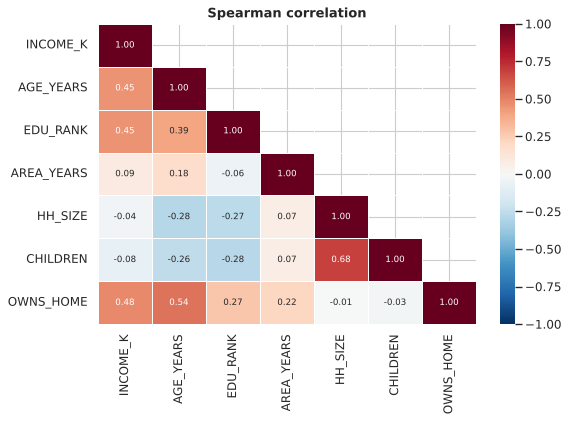

Correlation with income, strongest first:
OWNS_HOME     0.481
EDU_RANK      0.452
AGE_YEARS     0.446
AREA_YEARS    0.087
CHILDREN      0.082
HH_SIZE       0.035


In [ ]:
corr = tidy[numeric_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(7.5, 5.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor="white", annot_kws={"size": 8})
plt.title("Spearman correlation")
plt.tight_layout()
plt.show()

print("Correlation with income, strongest first:")
print(corr["INCOME_K"].drop("INCOME_K").abs().sort_values(ascending=False).round(3).to_string())

### Plot 8 - Education and occupation together

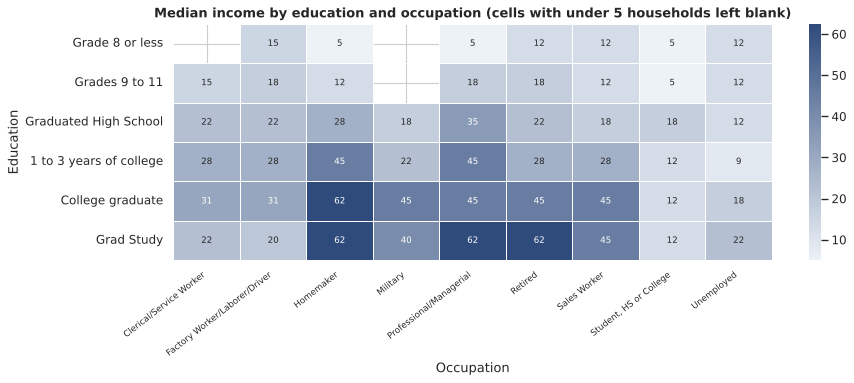

In [ ]:
grid = tidy.pivot_table(index="EDU_BAND", columns="OCCUPATION", values="INCOME_K",
                        aggfunc="median", observed=True)
count = tidy.pivot_table(index="EDU_BAND", columns="OCCUPATION", values="INCOME_K",
                         aggfunc="size", observed=True)
grid = grid.where(count >= 5)

plt.figure(figsize=(12, 5))
sns.heatmap(grid, cmap=SEQ, annot=True, fmt=".0f", linewidths=0.5, linecolor="white", annot_kws={"size": 8})
plt.title("Median income by education and occupation (cells with under 5 households left blank)")
plt.xlabel("Occupation")
plt.ylabel("Education")
plt.xticks(rotation=38, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

### Plot 9 - Age, dual income and household size together

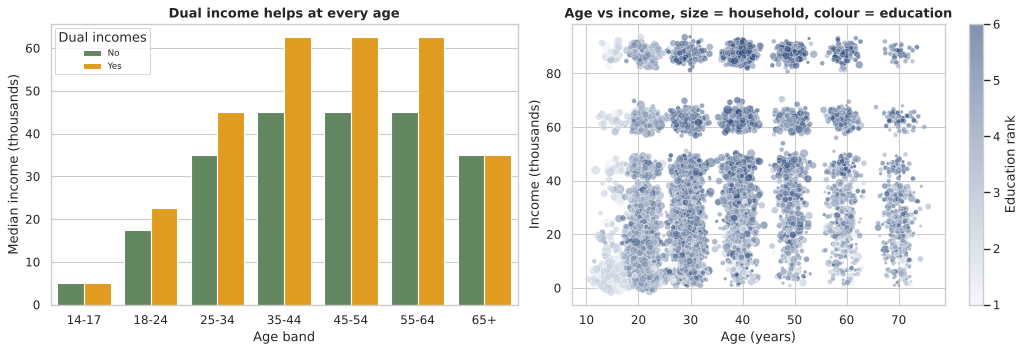

In [ ]:
combo = (tidy[tidy["DUAL_INCOMES_CLEAN"].isin(["Yes", "No"])]
         .groupby(["AGE_BAND", "DUAL_INCOMES_CLEAN"], observed=True)["INCOME_K"]
         .median().reset_index())

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

sns.barplot(data=combo, x="AGE_BAND", y="INCOME_K", hue="DUAL_INCOMES_CLEAN",
            palette=[GREEN, GOLD], errorbar=None, ax=axes[0])
axes[0].set_title("Dual income helps at every age")
axes[0].set_xlabel("Age band")
axes[0].set_ylabel("Median income (thousands)")
axes[0].legend(title="Dual incomes", fontsize=8)

rng = np.random.default_rng(23)
sample = tidy.dropna(subset=["AGE_YEARS", "INCOME_K", "HH_SIZE", "EDU_RANK"])
x = sample["AGE_YEARS"] + rng.normal(0, 1.5, len(sample))
y = sample["INCOME_K"] + rng.normal(0, 2.2, len(sample))

points = axes[1].scatter(x, y, c=sample["EDU_RANK"], s=sample["HH_SIZE"] * 10,
                         cmap=SEQ, alpha=0.6, edgecolor="white", linewidth=0.4)
axes[1].set_title("Age vs income, size = household, colour = education")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Income (thousands)")
plt.colorbar(points, ax=axes[1], label="Education rank")

plt.tight_layout()
plt.show()

## **9. Conclusion**

# **Phase 2 - Statistical Analysis and Clustering**

In [ ]:
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

data = tidy.copy()
data["DUAL"] = (data["DUAL_INCOMES_CLEAN"] == "Yes").astype(int)

cont_cols = ["INCOME_K", "AGE_YEARS", "EDU_RANK", "AREA_YEARS", "HH_SIZE", "CHILDREN"]
cat_cols = ["SEX", "MARITAL_STATUS", "OCCUPATION", "HOUSEHOLDER", "HOME_TYPE",
            "DUAL_INCOMES_CLEAN", "ETHNIC_CLASS", "LANGUAGE"]


def pval(p):
    """Readable p-value for tables."""
    return "< 0.001" if p < 0.001 else f"{p:.3f}"


def strength(r):
    """Common rule of thumb for the size of a correlation."""
    r = abs(r)
    return "very weak" if r < 0.1 else "weak" if r < 0.3 else "moderate" if r < 0.5 else "strong"


print("Rows:", len(data))
print("Numeric variables:", cont_cols)
print("Categorical variables:", cat_cols)

Rows: 8970
Numeric variables: ['INCOME_K', 'AGE_YEARS', 'EDU_RANK', 'AREA_YEARS', 'HH_SIZE', 'CHILDREN']
Categorical variables: ['SEX', 'MARITAL_STATUS', 'OCCUPATION', 'HOUSEHOLDER', 'HOME_TYPE', 'DUAL_INCOMES_CLEAN', 'ETHNIC_CLASS', 'LANGUAGE']


## **10. 1D Statistical Analysis (one variable at a time)**

### 10.1 Central tendency

In [ ]:
central = pd.DataFrame({
    "mean": data[cont_cols].mean(),
    "median": data[cont_cols].median(),
    "mode": data[cont_cols].mode().iloc[0],
    "trimmed_mean_10%": [stats.trim_mean(data[c].dropna(), 0.1) for c in cont_cols],
}).round(2)
central

,mean,median,mode,trimmed_mean_10%
INCOME_K,34.49,27.5,5.0,31.60
AGE_YEARS,34.67,29.5,29.5,33.11
EDU_RANK,3.84,4.0,4.0,3.83
AREA_YEARS,9.34,12.0,12.0,9.99
HH_SIZE,2.81,2.0,2.0,2.65
CHILDREN,0.66,0.0,0.0,0.45


### 10.2 Dispersion (spread)

In [ ]:
dispersion = pd.DataFrame({
    "min": data[cont_cols].min(),
    "max": data[cont_cols].max(),
    "range": data[cont_cols].max() - data[cont_cols].min(),
    "variance": data[cont_cols].var(),
    "std": data[cont_cols].std(),
    "IQR": data[cont_cols].quantile(0.75) - data[cont_cols].quantile(0.25),
    "MAD": [stats.median_abs_deviation(data[c].dropna()) for c in cont_cols],
    "CV_%": data[cont_cols].std() / data[cont_cols].mean() * 100,
    "std_error": data[cont_cols].sem(),
}).round(2)
dispersion

,min,max,range,variance,std,IQR,MAD,CV_%,std_error
INCOME_K,5.0,87.5,82.5,651.12,25.52,32.5,17.5,73.98,0.27
AGE_YEARS,15.5,70.0,54.5,234.83,15.32,18.5,10.0,44.20,0.16
EDU_RANK,1.0,6.0,5.0,1.53,1.23,2.0,1.0,32.17,0.01
AREA_YEARS,0.5,12.0,11.5,15.78,3.97,3.5,0.0,42.52,0.04
HH_SIZE,1.0,9.0,8.0,2.29,1.51,2.0,1.0,53.72,0.02
CHILDREN,0.0,9.0,9.0,1.17,1.08,1.0,0.0,162.81,0.01


### 10.3 Shape - skewness and kurtosis

In [ ]:
def skew_label(s):
    if abs(s) < 0.5:
        return "roughly symmetric"
    side = "right" if s > 0 else "left"
    return f"moderately {side}-skewed" if abs(s) < 1 else f"highly {side}-skewed"


def kurt_label(k):
    if abs(k) < 0.5:
        return "normal-like tails"
    return "heavy tails (leptokurtic)" if k > 0 else "light tails (platykurtic)"


shape = pd.DataFrame({
    "skewness": data[cont_cols].skew(),
    "excess_kurtosis": data[cont_cols].kurt(),
}).round(2)
shape["skew_meaning"] = shape["skewness"].apply(skew_label)
shape["kurtosis_meaning"] = shape["excess_kurtosis"].apply(kurt_label)
shape

,skewness,excess_kurtosis,skew_meaning,kurtosis_meaning
INCOME_K,0.70,-0.54,moderately right-skewed,light tails (platykurtic)
AGE_YEARS,0.80,-0.26,moderately right-skewed,normal-like tails
EDU_RANK,-0.09,-0.43,roughly symmetric,normal-like tails
AREA_YEARS,-1.10,-0.42,highly left-skewed,normal-like tails
HH_SIZE,1.09,1.47,highly right-skewed,heavy tails (leptokurtic)
CHILDREN,2.01,5.29,highly right-skewed,heavy tails (leptokurtic)


### 10.4 Position - percentiles and outliers

In [ ]:
percentiles = data[cont_cols].quantile([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T
percentiles.columns = ["P1", "P5", "P10", "Q1", "Median", "Q3", "P90", "P95", "P99"]
percentiles

,P1,P5,P10,Q1,Median,Q3,P90,P95,P99
INCOME_K,5.0,5.0,5.0,12.5,27.5,45.0,62.5,87.50,87.5
AGE_YEARS,15.5,15.5,21.0,21.0,29.5,39.5,59.5,70.00,70.0
EDU_RANK,1.0,2.0,2.0,3.0,4.0,5.0,6.0,6.00,6.0
AREA_YEARS,0.5,2.0,2.0,8.5,12.0,12.0,12.0,12.00,12.0
HH_SIZE,1.0,1.0,1.0,2.0,2.0,4.0,5.0,5.55,8.0
CHILDREN,0.0,0.0,0.0,0.0,0.0,1.0,2.0,3.00,4.0


In [ ]:
rows = []
for c in cont_cols:
    x = data[c].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    iqr_out = (x < low) | (x > high)
    rows.append({
        "variable": c,
        "lower_fence": low,
        "upper_fence": high,
        "IQR_outliers": int(iqr_out.sum()),
        "IQR_outliers_%": iqr_out.mean() * 100,
        "z>3_outliers": int((np.abs(stats.zscore(x)) > 3).sum()),
    })

outliers = pd.DataFrame(rows).set_index("variable").round(2)
outliers

,lower_fence,upper_fence,IQR_outliers,IQR_outliers_%,z>3_outliers
variable,,,,,
INCOME_K,-36.25,93.75,0,0.00,0
AGE_YEARS,-6.75,67.25,560,6.24,0
EDU_RANK,0.00,8.00,0,0.00,0
AREA_YEARS,3.25,17.25,1309,16.24,0
HH_SIZE,-1.00,7.00,107,1.19,107
CHILDREN,-1.50,2.50,609,6.79,201


### 10.5 Normality tests

In [ ]:
sample5k = data.sample(5000, random_state=23)

rows = []
for c in cont_cols:
    k2, p_k2 = stats.normaltest(data[c].dropna())
    w, p_w = stats.shapiro(sample5k[c].dropna())
    rows.append({
        "variable": c,
        "K2_statistic": round(k2, 1),
        "K2_p": pval(p_k2),
        "Shapiro_W": round(w, 3),
        "Shapiro_p": pval(p_w),
        "normal?": "yes" if min(p_k2, p_w) > 0.05 else "no",
    })

normality = pd.DataFrame(rows).set_index("variable")
normality

,K2_statistic,K2_p,Shapiro_W,Shapiro_p,normal?
variable,,,,,
INCOME_K,809.5,< 0.001,0.894,< 0.001,no
AGE_YEARS,789.0,< 0.001,0.890,< 0.001,no
EDU_RANK,124.9,< 0.001,0.931,< 0.001,no
AREA_YEARS,1202.7,< 0.001,0.671,< 0.001,no
HH_SIZE,1489.7,< 0.001,0.885,< 0.001,no
CHILDREN,3703.8,< 0.001,0.666,< 0.001,no


### Plot 10 - Q-Q plots

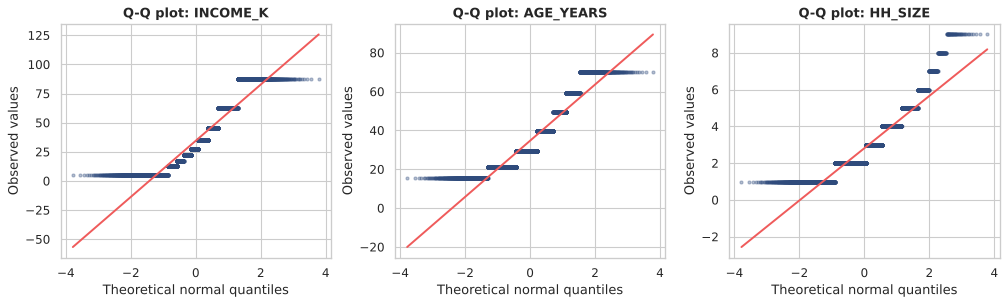

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, c in zip(axes, ["INCOME_K", "AGE_YEARS", "HH_SIZE"]):
    (theory, ordered), (slope, intercept, _) = stats.probplot(data[c], dist="norm")
    ax.scatter(theory, ordered, s=8, color=BLUE, alpha=0.35)
    ax.plot(theory, slope * theory + intercept, color=RED, linewidth=1.8)
    ax.set_title(f"Q-Q plot: {c}")
    ax.set_xlabel("Theoretical normal quantiles")
    ax.set_ylabel("Observed values")

plt.tight_layout()
plt.show()

### 10.6 Confidence intervals

In [ ]:
def mean_ci(x, level=0.95):
    x = x.dropna()
    t_crit = stats.t.ppf((1 + level) / 2, df=len(x) - 1)
    return x.mean(), x.mean() - t_crit * x.sem(), x.mean() + t_crit * x.sem()


def prop_ci(flags, level=0.95):
    p, n = flags.mean(), len(flags)
    z = stats.norm.ppf((1 + level) / 2)
    half = z * np.sqrt(p * (1 - p) / n)
    return p * 100, (p - half) * 100, (p + half) * 100


ci = pd.DataFrame(
    [mean_ci(data["INCOME_K"]), mean_ci(data["AGE_YEARS"]), mean_ci(data["HH_SIZE"]),
     prop_ci(data["INCOME_K"] >= 50), prop_ci(data["OWNS_HOME"] == 1), prop_ci(data["SEX"] == "F")],
    index=["Mean income (K)", "Mean age (years)", "Mean household size",
           "% earning 50K+", "% owning their home", "% women"],
    columns=["estimate", "95% CI lower", "95% CI upper"],
).round(2)
ci

,estimate,95% CI lower,95% CI upper
Mean income (K),34.49,33.96,35.02
Mean age (years),34.67,34.36,34.99
Mean household size,2.81,2.78,2.85
% earning 50K+,24.43,23.54,25.31
% owning their home,36.25,35.26,37.25
% women,54.69,53.66,55.72


### 10.7 Categorical variables

In [ ]:
rows = []
for c in cat_cols:
    p = data[c].value_counts(normalize=True)
    entropy = -(p * np.log2(p)).sum()
    rows.append({
        "variable": c,
        "categories": len(p),
        "mode": p.index[0],
        "mode_%": p.iloc[0] * 100,
        "entropy_bits": entropy,
        "evenness_0_to_1": entropy / np.log2(len(p)),
    })

cat_summary = pd.DataFrame(rows).set_index("variable").round(2)
cat_summary.sort_values("evenness_0_to_1")

,categories,mode,mode_%,entropy_bits,evenness_0_to_1
variable,,,,,
LANGUAGE,3,English,90.69,0.53,0.33
ETHNIC_CLASS,8,White,65.45,1.67,0.56
HOME_TYPE,5,House,60.37,1.52,0.65
DUAL_INCOMES_CLEAN,4,Not Married,59.44,1.42,0.71
MARITAL_STATUS,5,Single,42.39,1.83,0.79
OCCUPATION,9,Professional/Managerial,32.93,2.81,0.89
HOUSEHOLDER,3,Rent,43.47,1.52,0.96
SEX,2,F,54.69,0.99,0.99


In [ ]:
sex_counts = data["SEX"].value_counts()
chi2, p = stats.chisquare(sex_counts)

print(sex_counts.to_string())
print()
print(f"Chi-square = {chi2:.2f}, p-value = {pval(p)}")
print("Reject H0 (the split is not 50/50)" if p < 0.05 else "Fail to reject H0")

SEX
F    4906
M    4064

Chi-square = 79.04, p-value = < 0.001
Reject H0 (the split is not 50/50)


### Plot 11 - All numeric variables on one scale, and categorical evenness

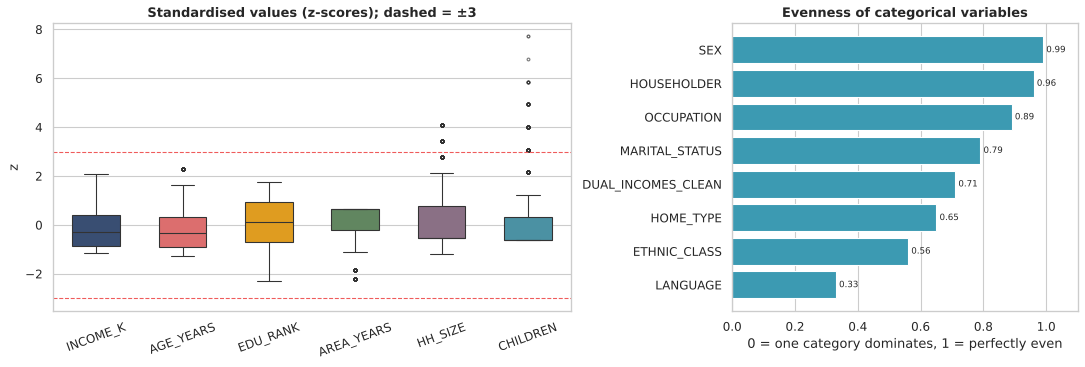

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})

z_scores = ((data[cont_cols] - data[cont_cols].mean()) / data[cont_cols].std()).melt(
    var_name="variable", value_name="z").dropna()
sns.boxplot(data=z_scores, x="variable", y="z", palette=PALETTE, width=0.55,
            flierprops={"markersize": 2.5, "alpha": 0.4}, ax=axes[0])
axes[0].axhline(3, color=RED, linestyle="--", linewidth=1)
axes[0].axhline(-3, color=RED, linestyle="--", linewidth=1)
axes[0].set_title("Standardised values (z-scores); dashed = ±3")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

even = cat_summary["evenness_0_to_1"].sort_values()
bars = axes[1].barh(even.index, even.values, color=TEAL)
axes[1].bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
axes[1].set_xlim(0, 1.1)
axes[1].set_title("Evenness of categorical variables")
axes[1].set_xlabel("0 = one category dominates, 1 = perfectly even")
axes[1].grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

## **11. 2D Statistical Analysis (two variables at a time)**

### 11.1 Covariance matrix

In [ ]:
data[cont_cols].cov().round(2)

,INCOME_K,AGE_YEARS,EDU_RANK,AREA_YEARS,HH_SIZE,CHILDREN
INCOME_K,651.12,122.96,13.54,8.90,-0.76,-1.68
AGE_YEARS,122.96,234.83,5.85,12.57,-6.22,-3.87
EDU_RANK,13.54,5.85,1.53,-0.29,-0.51,-0.36
AREA_YEARS,8.90,12.57,-0.29,15.78,0.37,0.27
HH_SIZE,-0.76,-6.22,-0.51,0.37,2.29,1.15
CHILDREN,-1.68,-3.87,-0.36,0.27,1.15,1.17


### 11.2 Correlation with income, with significance tests

In [ ]:
rows = []
for c in ["OWNS_HOME", "EDU_RANK", "AGE_YEARS", "DUAL", "AREA_YEARS", "CHILDREN", "HH_SIZE"]:
    pair = data[["INCOME_K", c]].dropna()
    r, p_r = stats.pearsonr(pair[c], pair["INCOME_K"])
    rho, p_rho = stats.spearmanr(pair[c], pair["INCOME_K"])
    tau, p_tau = stats.kendalltau(pair[c], pair["INCOME_K"])
    rows.append({
        "variable": c,
        "pearson_r": round(r, 3), "pearson_p": pval(p_r),
        "spearman_rho": round(rho, 3), "spearman_p": pval(p_rho),
        "kendall_tau": round(tau, 3), "kendall_p": pval(p_tau),
        "strength": strength(rho),
    })

corr_tests = pd.DataFrame(rows).set_index("variable")
corr_tests

,pearson_r,pearson_p,spearman_rho,spearman_p,kendall_tau,kendall_p,strength
variable,,,,,,,
OWNS_HOME,0.473,< 0.001,0.481,< 0.001,0.415,< 0.001,moderate
EDU_RANK,0.430,< 0.001,0.452,< 0.001,0.366,< 0.001,moderate
AGE_YEARS,0.314,< 0.001,0.446,< 0.001,0.354,< 0.001,moderate
DUAL,0.353,< 0.001,0.363,< 0.001,0.314,< 0.001,moderate
AREA_YEARS,0.087,< 0.001,0.087,< 0.001,0.070,< 0.001,very weak
CHILDREN,-0.061,< 0.001,-0.082,< 0.001,-0.067,< 0.001,very weak
HH_SIZE,-0.020,0.062,-0.035,< 0.001,-0.023,0.005,very weak


### 11.3 Simple regression

In [ ]:
edu_fit = stats.linregress(data["EDU_RANK"], data["INCOME_K"])
print("Income vs education")
print(f"  INCOME_K = {edu_fit.intercept:.2f} + {edu_fit.slope:.2f} x EDU_RANK")
print(f"  R-squared = {edu_fit.rvalue ** 2:.3f}, p-value = {pval(edu_fit.pvalue)}")


def r_squared(y, y_hat):
    return 1 - ((y - y_hat) ** 2).sum() / ((y - y.mean()) ** 2).sum()


age, inc = data["AGE_YEARS"], data["INCOME_K"]
lin_coef = np.polyfit(age, inc, 1)
quad_coef = np.polyfit(age, inc, 2)
peak_age = -quad_coef[1] / (2 * quad_coef[0])

print()
print("Income vs age")
print(f"  Straight line R-squared = {r_squared(inc, np.polyval(lin_coef, age)):.3f}")
print(f"  Quadratic     R-squared = {r_squared(inc, np.polyval(quad_coef, age)):.3f}")
print(f"  Quadratic curve peaks at age {peak_age:.1f}")

Income vs education
  INCOME_K = 0.40 + 8.88 x EDU_RANK
  R-squared = 0.185, p-value = < 0.001

Income vs age
  Straight line R-squared = 0.099
  Quadratic     R-squared = 0.207
  Quadratic curve peaks at age 48.5


### Plot 12 - Regression lines

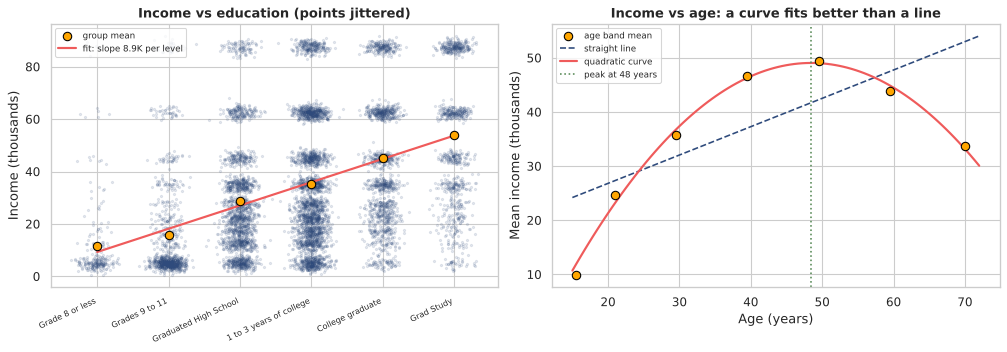

In [ ]:
rng = np.random.default_rng(23)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].scatter(data["EDU_RANK"] + rng.normal(0, 0.12, len(data)),
                data["INCOME_K"] + rng.normal(0, 1.5, len(data)), s=4, alpha=0.12, color=BLUE)
edu_means = data.groupby("EDU_RANK")["INCOME_K"].mean()
axes[0].scatter(edu_means.index, edu_means.values, s=60, color=GOLD, edgecolor="black", zorder=3, label="group mean")
xs = np.linspace(1, 6, 50)
axes[0].plot(xs, edu_fit.intercept + edu_fit.slope * xs, color=RED, linewidth=2,
             label=f"fit: slope {edu_fit.slope:.1f}K per level")
axes[0].set_xticks(range(1, 7))
axes[0].set_xticklabels(edu_order, rotation=25, ha="right", fontsize=7.5)
axes[0].set_ylabel("Income (thousands)")
axes[0].set_title("Income vs education (points jittered)")
axes[0].legend(fontsize=8)

age_means = data.groupby("AGE_YEARS")["INCOME_K"].mean()
xs = np.linspace(15, 72, 100)
axes[1].scatter(age_means.index, age_means.values, s=60, color=GOLD, edgecolor="black", zorder=3, label="age band mean")
axes[1].plot(xs, np.polyval(lin_coef, xs), color=BLUE, linestyle="--", label="straight line")
axes[1].plot(xs, np.polyval(quad_coef, xs), color=RED, linewidth=2, label="quadratic curve")
axes[1].axvline(peak_age, color=GREEN, linestyle=":", label=f"peak at {peak_age:.0f} years")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Mean income (thousands)")
axes[1].set_title("Income vs age: a curve fits better than a line")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 11.4 Categorical vs categorical - chi-square test and Cramér's V

In [ ]:
def chi_square_test(a, b):
    table = pd.crosstab(data[a], data[b])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return chi2, p, dof, v, (expected < 5).mean() * 100


rows = []
for c in ["EDUCATION", "AGE", "OCCUPATION", "HOUSEHOLDER", "MARITAL_STATUS", "HOME_TYPE",
          "DUAL_INCOMES_CLEAN", "ETHNIC_CLASS", "LANGUAGE", "SEX"]:
    chi2, p, dof, v, low = chi_square_test("INCOME_BAND", c)
    rows.append({"INCOME_BAND vs": c, "chi_square": round(chi2, 1), "dof": dof, "p_value": pval(p),
                 "cramers_v": round(v, 3), "cells_expected<5_%": round(low, 1)})

chi_table = pd.DataFrame(rows).set_index("INCOME_BAND vs").sort_values("cramers_v", ascending=False)
chi_table

,chi_square,dof,p_value,cramers_v,cells_expected<5_%
INCOME_BAND vs,,,,,
HOUSEHOLDER,3761.5,16,< 0.001,0.458,0.0
AGE,4274.8,48,< 0.001,0.282,0.0
EDUCATION,3206.3,40,< 0.001,0.267,0.0
MARITAL_STATUS,2498.0,32,< 0.001,0.264,0.0
DUAL_INCOMES_CLEAN,1881.5,24,< 0.001,0.264,0.0
OCCUPATION,3814.0,64,< 0.001,0.231,0.0
HOME_TYPE,852.7,32,< 0.001,0.154,0.0
LANGUAGE,166.7,16,< 0.001,0.096,0.0
ETHNIC_CLASS,355.8,56,< 0.001,0.075,12.5


### Plot 13 - Cramér's V between every pair of categorical variables

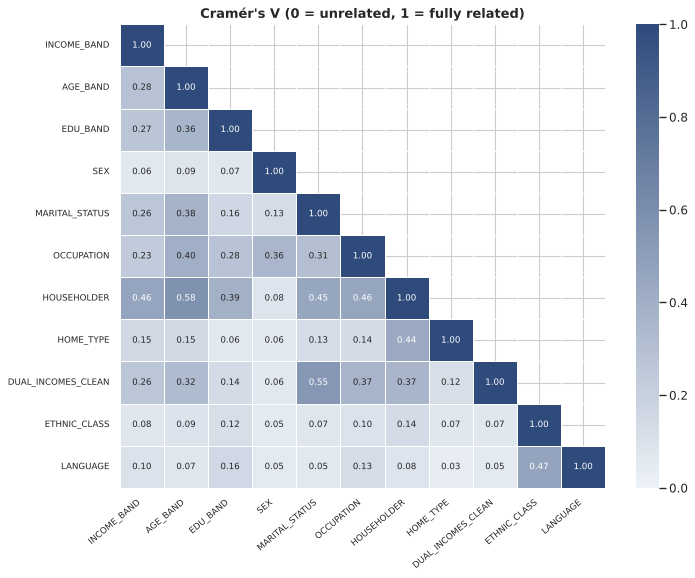

In [ ]:
assoc_cols = ["INCOME_BAND", "AGE_BAND", "EDU_BAND"] + cat_cols
cramers = pd.DataFrame(index=assoc_cols, columns=assoc_cols, dtype=float)
for a in assoc_cols:
    for b in assoc_cols:
        cramers.loc[a, b] = 1.0 if a == b else chi_square_test(a, b)[3]

plt.figure(figsize=(9.5, 7.5))
sns.heatmap(cramers, mask=np.triu(np.ones_like(cramers, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap=SEQ, vmin=0, vmax=1, linewidths=0.5, linecolor="white", annot_kws={"size": 8})
plt.title("Cramér's V (0 = unrelated, 1 = fully related)")
plt.xticks(rotation=40, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

### 11.5 Numeric vs categorical - comparing income across groups

In [ ]:
men = data.loc[data["SEX"] == "M", "INCOME_K"]
women = data.loc[data["SEX"] == "F", "INCOME_K"]

t, p_t = stats.ttest_ind(men, women, equal_var=False)
u, p_u = stats.mannwhitneyu(men, women)
pooled_sd = np.sqrt(((len(men) - 1) * men.var() + (len(women) - 1) * women.var()) / (len(men) + len(women) - 2))
cohens_d = (men.mean() - women.mean()) / pooled_sd

print(f"Mean income: men {men.mean():.2f}K, women {women.mean():.2f}K")
print(f"Welch t-test: t = {t:.2f}, p = {pval(p_t)}")
print(f"Mann-Whitney U: U = {u:.0f}, p = {pval(p_u)}")
print(f"Cohen's d = {cohens_d:.3f}")

Mean income: men 35.48K, women 33.67K
Welch t-test: t = 3.33, p = < 0.001
Mann-Whitney U: U = 10417220, p = < 0.001
Cohen's d = 0.071


In [ ]:
rows = []
for c in ["OCCUPATION", "MARITAL_STATUS", "HOUSEHOLDER", "HOME_TYPE", "DUAL_INCOMES_CLEAN", "ETHNIC_CLASS", "LANGUAGE"]:
    groups = [g["INCOME_K"].values for _, g in data.groupby(c)]
    f, p_f = stats.f_oneway(*groups)
    h, p_h = stats.kruskal(*groups)
    ss_between = sum(len(g) * (g.mean() - data["INCOME_K"].mean()) ** 2 for g in groups)
    ss_total = ((data["INCOME_K"] - data["INCOME_K"].mean()) ** 2).sum()
    rows.append({"income by": c, "groups": len(groups), "anova_F": round(f, 1), "anova_p": pval(p_f),
                 "kruskal_H": round(h, 1), "kruskal_p": pval(p_h), "eta_squared": round(ss_between / ss_total, 3)})

anova_table = pd.DataFrame(rows).set_index("income by").sort_values("eta_squared", ascending=False)
anova_table

,groups,anova_F,anova_p,kruskal_H,kruskal_p,eta_squared
income by,,,,,,
HOUSEHOLDER,3,1407.1,< 0.001,2413.9,< 0.001,0.239
MARITAL_STATUS,5,576.2,< 0.001,2108.3,< 0.001,0.205
OCCUPATION,9,263.0,< 0.001,2163.8,< 0.001,0.190
DUAL_INCOMES_CLEAN,4,676.9,< 0.001,1818.7,< 0.001,0.185
HOME_TYPE,5,142.6,< 0.001,452.1,< 0.001,0.060
ETHNIC_CLASS,8,41.8,< 0.001,263.5,< 0.001,0.032
LANGUAGE,3,64.5,< 0.001,143.3,< 0.001,0.014


### Plot 14 - Mean income by group with 95% confidence intervals

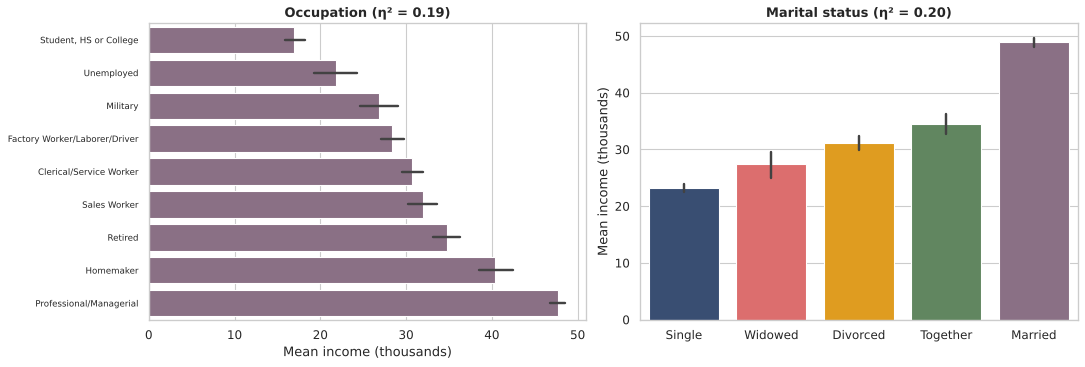

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

occ_order = data.groupby("OCCUPATION")["INCOME_K"].mean().sort_values().index
sns.barplot(data=data, y="OCCUPATION", x="INCOME_K", order=occ_order, color=PURPLE,
            errorbar=("ci", 95), ax=axes[0])
axes[0].set_title(f"Occupation (η² = {anova_table.loc['OCCUPATION', 'eta_squared']:.2f})")
axes[0].set_xlabel("Mean income (thousands)")
axes[0].set_ylabel("")
axes[0].tick_params(axis="y", labelsize=8)

mar_order = data.groupby("MARITAL_STATUS")["INCOME_K"].mean().sort_values().index
sns.barplot(data=data, x="MARITAL_STATUS", y="INCOME_K", order=mar_order, palette=PALETTE,
            errorbar=("ci", 95), ax=axes[1])
axes[1].set_title(f"Marital status (η² = {anova_table.loc['MARITAL_STATUS', 'eta_squared']:.2f})")
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean income (thousands)")

plt.tight_layout()
plt.show()

## **12. 3D Statistical Analysis (three variables together)**

### 12.1 Three-way tables

In [ ]:
three_way = data.pivot_table(index="EDU_BAND", columns="SEX", values="INCOME_K",
                             aggfunc="mean", observed=True).round(1)
three_way["gap (M - F)"] = three_way["M"] - three_way["F"]
three_way

SEX,F,M,gap (M - F)
EDU_BAND,,,
Grade 8 or less,9.5,15.3,5.8
Grades 9 to 11,14.2,18.2,4.0
Graduated High School,29.5,28.1,-1.4
1 to 3 years of college,35.5,34.6,-0.9
College graduate,45.0,44.9,-0.1
Grad Study,52.0,55.9,3.9


In [ ]:
data["INCOME_LEVEL"] = pd.cut(data["INCOME_K"], [0, 25, 50, 100],
                              labels=["Low (< 25K)", "Middle (25-50K)", "High (50K+)"])

ownership = data.pivot_table(index="AGE_BAND", columns="INCOME_LEVEL", values="OWNS_HOME",
                             aggfunc="mean", observed=True).mul(100).round(1)
print("% of households owning their home, by age band and income level")
ownership

% of households owning their home, by age band and income level


INCOME_LEVEL,Low (< 25K),Middle (25-50K),High (50K+)
AGE_BAND,,,
14-17,1.1,13.3,20.5
18-24,6.6,13.2,15.6
25-34,10.0,26.0,56.7
35-44,19.1,49.1,79.4
45-54,41.5,64.9,86.1
55-64,50.3,81.1,93.8
65+,60.7,82.7,92.8


### 12.2 Two-way ANOVA - education × sex → income

In [ ]:
two_way = smf.ols("INCOME_K ~ C(EDUCATION) * C(SEX)", data=data).fit()
aov = anova_lm(two_way, typ=2)
aov["partial_eta_sq"] = aov["sum_sq"] / (aov["sum_sq"] + aov.loc["Residual", "sum_sq"])
aov["p_value"] = aov["PR(>F)"].apply(lambda p: pval(p) if pd.notna(p) else "")
aov.loc["Residual", "partial_eta_sq"] = np.nan
aov[["sum_sq", "df", "F", "p_value", "partial_eta_sq"]].round(3)

,sum_sq,df,F,p_value,partial_eta_sq
C(EDUCATION),1087660.164,5.0,411.621,< 0.001,0.187
C(SEX),370.203,1.0,0.701,0.403,0.000
C(EDUCATION):C(SEX),10895.068,5.0,4.123,< 0.001,0.002
Residual,4734097.915,8958.0,NaN,,NaN


### Plot 15 - Interaction plot

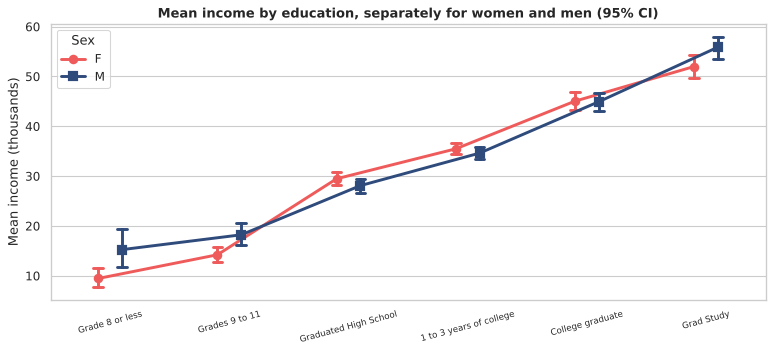

In [ ]:
plt.figure(figsize=(10, 4.6))
sns.pointplot(data=data, x="EDU_BAND", y="INCOME_K", hue="SEX", palette=[RED, BLUE],
              errorbar=("ci", 95), dodge=0.2, markers=["o", "s"], capsize=0.08)
plt.title("Mean income by education, separately for women and men (95% CI)")
plt.xlabel("")
plt.ylabel("Mean income (thousands)")
plt.xticks(rotation=15, fontsize=8)
plt.legend(title="Sex")
plt.tight_layout()
plt.show()

### 12.3 Partial correlation - removing the effect of age

In [ ]:
def partial_corr(x, y, control="AGE"):
    d = data[[x, y, control]].dropna()
    x_left = d[x] - d.groupby(control)[x].transform("mean")
    y_left = d[y] - d.groupby(control)[y].transform("mean")
    return stats.pearsonr(x_left, y_left)


rows = []
for c in ["OWNS_HOME", "EDU_RANK", "DUAL", "HH_SIZE", "CHILDREN", "AREA_YEARS"]:
    pair = data[[c, "INCOME_K"]].dropna()
    r_plain = stats.pearsonr(pair[c], pair["INCOME_K"])[0]
    r_part, p_part = partial_corr(c, "INCOME_K")
    rows.append({"variable vs income": c, "plain_r": round(r_plain, 3), "partial_r (age removed)": round(r_part, 3),
                 "partial_p": pval(p_part), "change": round(r_part - r_plain, 3)})

partial = pd.DataFrame(rows).set_index("variable vs income")
partial

,plain_r,partial_r (age removed),partial_p,change
variable vs income,,,,
OWNS_HOME,0.473,0.356,< 0.001,-0.117
EDU_RANK,0.430,0.264,< 0.001,-0.166
DUAL,0.353,0.249,< 0.001,-0.104
HH_SIZE,-0.020,0.103,< 0.001,0.122
CHILDREN,-0.061,0.034,0.001,0.095
AREA_YEARS,0.087,0.049,< 0.001,-0.038


In [ ]:
strata = (data.groupby("AGE_BAND", observed=True)
              .apply(lambda g: pd.Series({"households": len(g),
                                          "spearman_edu_income": g["EDU_RANK"].corr(g["INCOME_K"], method="spearman")}))
              .round(3))
strata["households"] = strata["households"].astype(int)
strata

,households,spearman_edu_income
AGE_BAND,,
14-17,855,0.082
18-24,2129,0.065
25-34,2249,0.280
35-44,1615,0.363
45-54,922,0.291
55-64,640,0.460
65+,560,0.338


### 12.4 Multiple regression

In [ ]:
formulas = {
    "M1: education": "INCOME_K ~ EDU_RANK",
    "M2: + age": "INCOME_K ~ EDU_RANK + AGE_YEARS",
    "M3: + age squared": "INCOME_K ~ EDU_RANK + AGE_YEARS + I(AGE_YEARS ** 2)",
    "M4: + dual income + sex": "INCOME_K ~ EDU_RANK + AGE_YEARS + I(AGE_YEARS ** 2) + DUAL + C(SEX)",
}
fits = {name: smf.ols(f, data=data).fit() for name, f in formulas.items()}

pd.DataFrame({
    "R_squared": {n: m.rsquared for n, m in fits.items()},
    "adj_R_squared": {n: m.rsquared_adj for n, m in fits.items()},
    "AIC": {n: m.aic for n, m in fits.items()},
}).round(3)

,R_squared,adj_R_squared,AIC
M1: education,0.185,0.185,81740.827
M2: + age,0.221,0.221,81332.774
M3: + age squared,0.260,0.260,80869.784
M4: + dual income + sex,0.308,0.308,80272.839


In [ ]:
best = fits["M4: + dual income + sex"]
pd.DataFrame({"coefficient": best.params, "std_error": best.bse,
              "t": best.tvalues, "p_value": best.pvalues.apply(pval)}).round(3)

,coefficient,std_error,t,p_value
Intercept,-22.989,1.455,-15.802,< 0.001
C(SEX)[T.M],1.584,0.452,3.503,< 0.001
EDU_RANK,5.437,0.212,25.646,< 0.001
AGE_YEARS,1.547,0.091,17.017,< 0.001
I(AGE_YEARS ** 2),-0.015,0.001,-13.829,< 0.001
DUAL,13.841,0.558,24.792,< 0.001


### Plot 16 - 3D surface: age, education and income

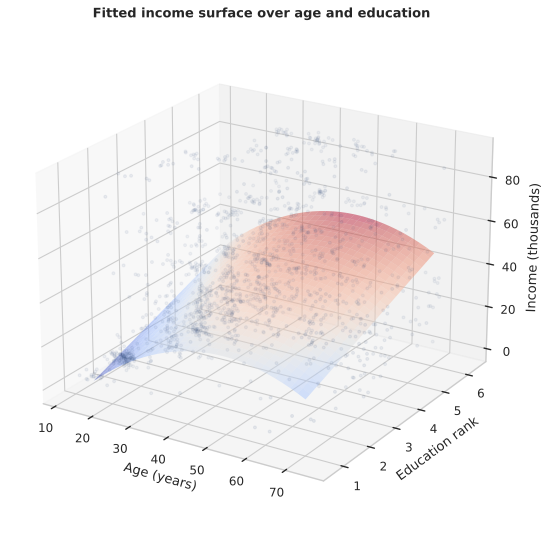

In [ ]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3D projection)

rng = np.random.default_rng(23)
pts = data.sample(1500, random_state=23)
m3 = fits["M3: + age squared"]

age_grid, edu_grid = np.meshgrid(np.linspace(15, 70, 30), np.linspace(1, 6, 30))
surface = m3.predict(pd.DataFrame({"AGE_YEARS": age_grid.ravel(), "EDU_RANK": edu_grid.ravel()})).values.reshape(age_grid.shape)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection="3d")
ax.scatter(pts["AGE_YEARS"] + rng.normal(0, 1.5, len(pts)), pts["EDU_RANK"] + rng.normal(0, 0.12, len(pts)),
           pts["INCOME_K"] + rng.normal(0, 1.5, len(pts)), color=BLUE, s=7, alpha=0.3)
ax.plot_surface(age_grid, edu_grid, surface, cmap="coolwarm", alpha=0.45, edgecolor="none")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Education rank")
ax.set_zlabel("Income (thousands)")
ax.set_title("Fitted income surface over age and education")
ax.view_init(elev=22, azim=-58)
plt.tight_layout()
plt.show()

### Plot 17 - 3D bar chart: mean income for every age band × education level

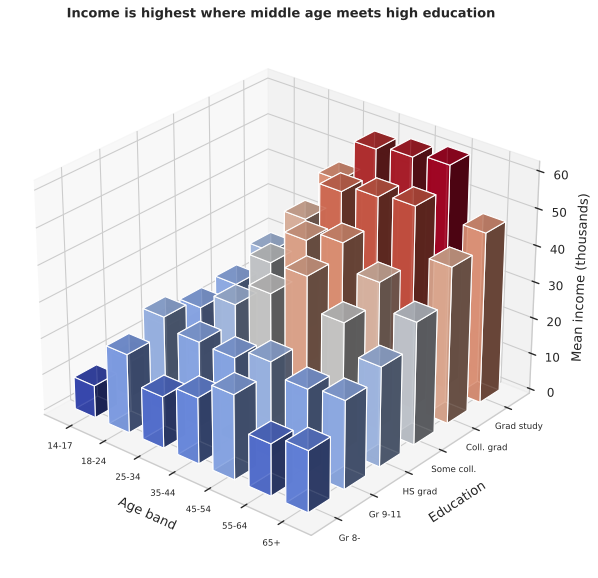

EDU_BAND,Grade 8 or less,Grades 9 to 11,Graduated High School,1 to 3 years of college,College graduate,Grad Study
AGE_BAND,,,,,,
14-17,8.9,10.0,14.4,8.4,NaN,NaN
18-24,21.7,26.3,23.4,24.5,28.5,28.9
25-34,14.2,23.5,28.2,34.3,41.1,46.8
35-44,18.1,23.2,35.0,44.1,52.2,58.7
45-54,23.2,26.2,43.6,47.2,54.3,60.0
55-64,14.2,23.0,35.0,40.4,55.4,61.3
65+,16.8,24.1,27.2,33.6,42.9,46.8


In [ ]:
cube = data.pivot_table(index="AGE_BAND", columns="EDU_BAND", values="INCOME_K", aggfunc="mean", observed=True)

xi, yi = np.meshgrid(np.arange(cube.shape[0]), np.arange(cube.shape[1]), indexing="ij")
heights = cube.values.ravel()
colours = plt.cm.coolwarm((heights - np.nanmin(heights)) / (np.nanmax(heights) - np.nanmin(heights)))

fig = plt.figure(figsize=(11, 7.5))
ax = fig.add_subplot(projection="3d")
ax.bar3d(xi.ravel(), yi.ravel(), np.zeros_like(heights), 0.6, 0.6, np.nan_to_num(heights),
         color=colours, shade=True, alpha=0.9)
ax.set_xticks(np.arange(cube.shape[0]) + 0.3)
ax.set_xticklabels(cube.index.astype(str), fontsize=8)
ax.set_yticks(np.arange(cube.shape[1]) + 0.3)
ax.set_yticklabels(["Gr 8-", "Gr 9-11", "HS grad", "Some coll.", "Coll. grad", "Grad study"], fontsize=8)
ax.set_xlabel("Age band", labelpad=8)
ax.set_ylabel("Education", labelpad=10)
ax.set_zlabel("Mean income (thousands)")
ax.set_title("Income is highest where middle age meets high education")
ax.view_init(elev=28, azim=-50)
plt.tight_layout()
plt.show()

cube.round(1)

## **13. K-Means Clustering**

### 13.1 Feature selection and scaling

In [ ]:
features = ["INCOME_K", "AGE_YEARS", "EDU_RANK", "HH_SIZE", "CHILDREN", "OWNS_HOME", "DUAL"]

scaler = StandardScaler()
X = scaler.fit_transform(data[features])

pd.DataFrame({
    "mean_before": data[features].mean(), "std_before": data[features].std(),
    "mean_after": X.mean(axis=0), "std_after": X.std(axis=0),
}).round(2)

,mean_before,std_before,mean_after,std_after
INCOME_K,34.49,25.52,0.0,1.0
AGE_YEARS,34.67,15.32,0.0,1.0
EDU_RANK,3.84,1.23,-0.0,1.0
HH_SIZE,2.81,1.51,0.0,1.0
CHILDREN,0.66,1.08,0.0,1.0
OWNS_HOME,0.36,0.48,-0.0,1.0
DUAL,0.25,0.43,-0.0,1.0


### 13.2 Choosing the number of clusters (k)

In [ ]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=23).fit(X)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(X, km.labels_),
                 "davies_bouldin": davies_bouldin_score(X, km.labels_),
                 "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
                 "smallest_cluster_%": np.bincount(km.labels_).min() / len(X) * 100})

k_scores = pd.DataFrame(rows).set_index("k").round(3)
k_scores

,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_%
k,,,,,
2,47173.883,0.259,1.625,2968.733,40.323
3,38096.861,0.250,1.435,2906.058,20.725
4,32505.176,0.264,1.370,2784.519,19.220
5,29692.176,0.240,1.414,2498.318,7.258
6,27144.195,0.233,1.414,2354.308,9.376
7,24911.375,0.255,1.412,2271.428,7.001
8,23503.001,0.252,1.360,2140.097,5.641
9,22130.505,0.224,1.425,2057.962,5.496
10,20917.064,0.228,1.348,1992.961,4.916


### Plot 18 - Elbow, silhouette and Davies-Bouldin

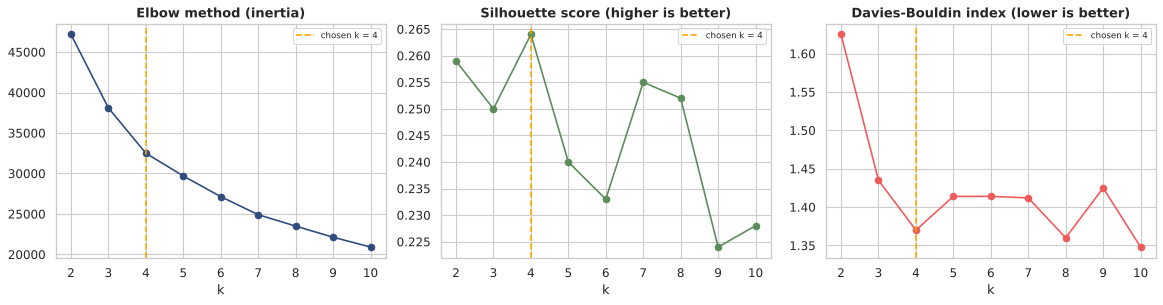

In [ ]:
K = 4

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, colour, title in zip(axes, ["inertia", "silhouette", "davies_bouldin"], [BLUE, GREEN, RED],
                                  ["Elbow method (inertia)", "Silhouette score (higher is better)",
                                   "Davies-Bouldin index (lower is better)"]):
    ax.plot(k_scores.index, k_scores[col], marker="o", color=colour)
    ax.axvline(K, color=GOLD, linestyle="--", label=f"chosen k = {K}")
    ax.set_title(title)
    ax.set_xlabel("k")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### 13.3 Final model and cluster profiles

In [ ]:
def number_by_income(labels):
    order = pd.Series(data["INCOME_K"].values).groupby(labels).mean().sort_values().index
    return pd.Series(labels).map({old: new for new, old in enumerate(order)}).values


kmeans = KMeans(n_clusters=K, n_init=10, random_state=23).fit(X)
data["KMEANS"] = number_by_income(kmeans.labels_)

print(f"Silhouette = {silhouette_score(X, data['KMEANS']):.3f}")
print(f"Iterations to converge = {kmeans.n_iter_}")


def profile(label_col):
    prof = data.groupby(label_col)[features].mean()
    prof.insert(0, "households", data[label_col].value_counts().sort_index())
    prof.insert(1, "share_%", prof["households"] / len(data) * 100)
    prof["male_%"] = data.groupby(label_col)["SEX"].apply(lambda s: (s == "M").mean() * 100)
    prof["married_%"] = data.groupby(label_col)["MARITAL_STATUS"].apply(lambda s: (s == "Married").mean() * 100)
    prof["top_occupation"] = data.groupby(label_col)["OCCUPATION"].agg(lambda s: s.mode().iat[0])
    return prof.round(2)


km_profile = profile("KMEANS")
km_profile

Silhouette = 0.264
Iterations to converge = 22


,households,share_%,INCOME_K,AGE_YEARS,EDU_RANK,HH_SIZE,CHILDREN,OWNS_HOME,DUAL,male_%,married_%,top_occupation
KMEANS,,,,,,,,,,,,
0,1724,19.22,18.58,22.11,2.57,4.72,2.06,0.10,0.09,40.66,17.81,"Student, HS or College"
1,3436,38.31,24.84,29.29,3.90,2.08,0.13,0.02,0.03,51.69,8.09,Professional/Managerial
2,1869,20.84,45.97,51.56,4.29,2.21,0.29,0.93,0.00,41.41,50.03,Professional/Managerial
3,1941,21.64,54.65,39.10,4.42,3.01,0.74,0.67,1.00,41.89,92.94,Professional/Managerial


In [ ]:
KM_NAMES = {0: "Young, large families", 1: "Young singles, renting",
            2: "Older homeowners, one income", 3: "Dual-income couples"}
data["KMEANS_NAME"] = data["KMEANS"].map(KM_NAMES)
data["KMEANS_NAME"].value_counts()

KMEANS_NAME
Young singles, renting          3436
Dual-income couples             1941
Older homeowners, one income    1869
Young, large families           1724
Name: count, dtype: int64

### Plot 19 - Clusters on the first two principal components, and cluster profiles

Variance kept by PC1 and PC2: [35.6 24.7] %
Total: 60.4 %


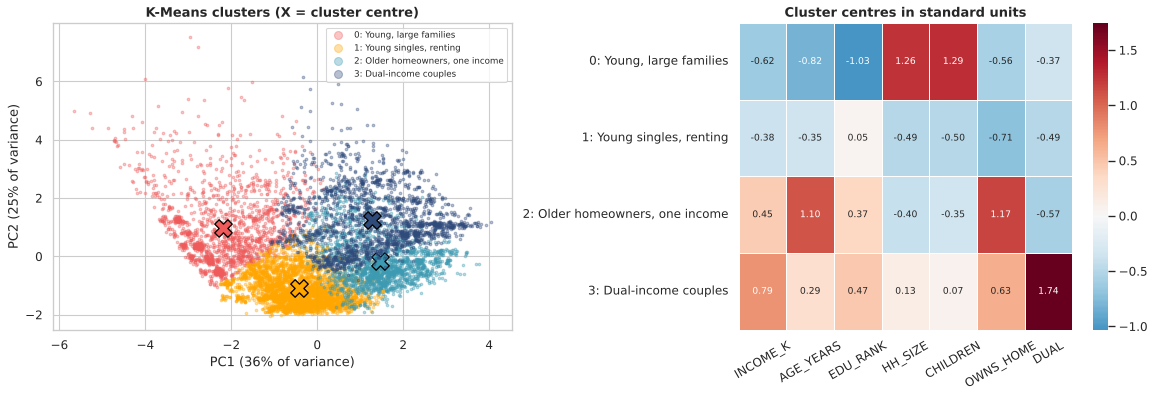

In [ ]:
pca = PCA(n_components=2, random_state=23)
pc = pca.fit_transform(X)
print("Variance kept by PC1 and PC2:", (pca.explained_variance_ratio_ * 100).round(1), "%")
print("Total:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

CLUSTER_COLOURS = [RED, GOLD, TEAL, BLUE, GREEN, PURPLE]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})

jitter = np.random.default_rng(23).normal(0, 0.06, pc.shape)
for c in range(K):
    m = data["KMEANS"].values == c
    axes[0].scatter(pc[m, 0] + jitter[m, 0], pc[m, 1] + jitter[m, 1], s=6, alpha=0.35,
                    color=CLUSTER_COLOURS[c], label=f"{c}: {KM_NAMES[c]}")
    centre = pc[m].mean(axis=0)
    axes[0].scatter(*centre, s=260, marker="X", color=CLUSTER_COLOURS[c], edgecolor="black", linewidth=1.2)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.0f}% of variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.0f}% of variance)")
axes[0].set_title("K-Means clusters (X = cluster centre)")
axes[0].legend(fontsize=8, markerscale=3, loc="best")

z_profile = pd.DataFrame(X, columns=features).groupby(data["KMEANS"].values).mean()
z_profile.index = [f"{c}: {KM_NAMES[c]}" for c in z_profile.index]
sns.heatmap(z_profile, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5,
            linecolor="white", annot_kws={"size": 8.5}, ax=axes[1])
axes[1].set_title("Cluster centres in standard units")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Plot 20 - Checking the clusters against variables that were not used

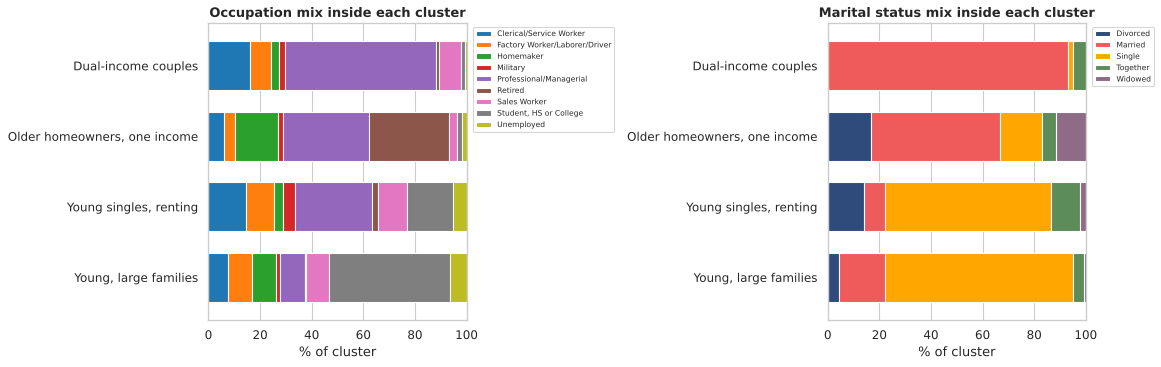

Chi-square test, cluster vs occupation:     Cramer's V = 0.414
Chi-square test, cluster vs marital status: Cramer's V = 0.453


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

for ax, col, title in zip(axes, ["OCCUPATION", "MARITAL_STATUS"], ["Occupation", "Marital status"]):
    mix = pd.crosstab(data["KMEANS_NAME"], data[col], normalize="index") * 100
    mix = mix.loc[[KM_NAMES[c] for c in range(K)]]
    mix.plot(kind="barh", stacked=True, ax=ax, width=0.7,
             color=sns.color_palette("tab10" if col == "OCCUPATION" else PALETTE, mix.shape[1]))
    ax.set_title(f"{title} mix inside each cluster")
    ax.set_xlabel("% of cluster")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)
    ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
    ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

print("Chi-square test, cluster vs occupation:     Cramer's V =", round(chi_square_test("KMEANS", "OCCUPATION")[3], 3))
print("Chi-square test, cluster vs marital status: Cramer's V =", round(chi_square_test("KMEANS", "MARITAL_STATUS")[3], 3))

## **14. Hierarchical Clustering**

### 14.1 Ward linkage and the dendrogram

In [ ]:
Z_ward = linkage(X, method="ward")

last = Z_ward[-10:, 2][::-1]
merges = pd.DataFrame({"clusters_before_merge": range(2, 12), "merge_height": last})
merges["jump_to_next_merge"] = merges["merge_height"] - merges["merge_height"].shift(-1)
merges.round(2)

,clusters_before_merge,merge_height,jump_to_next_merge
0,2,166.02,46.07
1,3,119.96,1.89
2,4,118.06,40.17
3,5,77.89,10.83
4,6,67.06,8.48
5,7,58.58,6.53
6,8,52.05,0.78
7,9,51.27,3.73
8,10,47.53,1.81
9,11,45.72,NaN


### Plot 21 - Dendrogram and merge heights

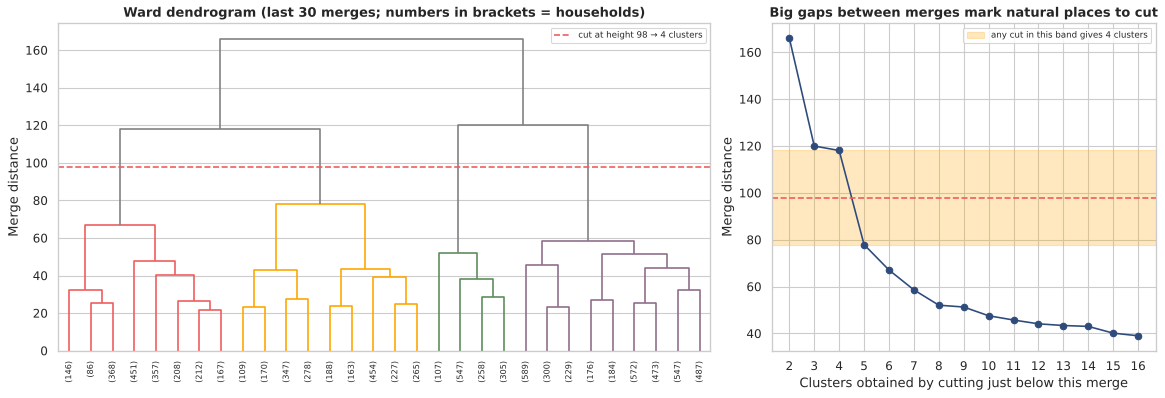

In [ ]:
cut_height = (Z_ward[-K, 2] + Z_ward[-(K - 1), 2]) / 2

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.7, 1]})

dendrogram(Z_ward, truncate_mode="lastp", p=30, color_threshold=cut_height, above_threshold_color="grey",
           show_leaf_counts=True, leaf_rotation=90, leaf_font_size=7.5, ax=axes[0])
axes[0].axhline(cut_height, color=RED, linestyle="--", label=f"cut at height {cut_height:.0f} → {K} clusters")
axes[0].set_title("Ward dendrogram (last 30 merges; numbers in brackets = households)")
axes[0].set_ylabel("Merge distance")
axes[0].legend(fontsize=8)
axes[0].grid(axis="x", visible=False)

heights = Z_ward[-15:, 2][::-1]
axes[1].plot(range(2, 17), heights, marker="o", color=BLUE)
axes[1].axhspan(Z_ward[-K, 2], Z_ward[-(K - 1), 2], color=GOLD, alpha=0.25,
                label=f"any cut in this band gives {K} clusters")
axes[1].axhline(cut_height, color=RED, linestyle="--")
axes[1].set_xlabel("Clusters obtained by cutting just below this merge")
axes[1].set_ylabel("Merge distance")
axes[1].set_title("Big gaps between merges mark natural places to cut")
axes[1].set_xticks(range(2, 17))
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
rows = []
for k in range(2, 8):
    lab = fcluster(Z_ward, t=k, criterion="maxclust")
    rows.append({"k": k, "silhouette": silhouette_score(X, lab), "davies_bouldin": davies_bouldin_score(X, lab),
                 "smallest_cluster_%": np.bincount(lab)[1:].min() / len(X) * 100})
pd.DataFrame(rows).set_index("k").round(3)

,silhouette,davies_bouldin,smallest_cluster_%
k,,,
2,0.238,1.774,46.778
3,0.207,1.505,13.567
4,0.248,1.453,13.567
5,0.266,1.423,10.078
6,0.266,1.435,6.689
7,0.201,1.584,6.689


### 14.2 Comparing linkage methods

In [ ]:
distances = pdist(X)

rows = []
for method in ["single", "complete", "average", "ward"]:
    Z = Z_ward if method == "ward" else linkage(X, method=method)
    coph, _ = cophenet(Z, distances)
    lab = fcluster(Z, t=K, criterion="maxclust")
    sizes = np.bincount(lab)[1:]
    rows.append({"linkage": method, "cophenetic_corr": coph, "silhouette_k4": silhouette_score(X, lab),
                 "largest_cluster_%": sizes.max() / len(X) * 100, "cluster_sizes": sorted(sizes, reverse=True)})

linkage_table = pd.DataFrame(rows).set_index("linkage").round(3)
linkage_table

,cophenetic_corr,silhouette_k4,largest_cluster_%,cluster_sizes
linkage,,,,
single,0.547,0.532,99.955,"[8966, 2, 1, 1]"
complete,0.558,0.191,83.489,"[7489, 1356, 114, 11]"
average,0.734,0.368,97.414,"[8738, 219, 10, 3]"
ward,0.559,0.248,39.654,"[3557, 2201, 1995, 1217]"


### 14.3 Ward cluster profiles

In [ ]:
data["WARD"] = number_by_income(fcluster(Z_ward, t=K, criterion="maxclust"))
print(f"Silhouette = {silhouette_score(X, data['WARD']):.3f}")
ward_profile = profile("WARD")
ward_profile

Silhouette = 0.248


,households,share_%,INCOME_K,AGE_YEARS,EDU_RANK,HH_SIZE,CHILDREN,OWNS_HOME,DUAL,male_%,married_%,top_occupation
WARD,,,,,,,,,,,,
0,1217,13.57,11.19,19.16,2.35,4.60,2.02,0.01,0.0,38.78,6.24,"Student, HS or College"
1,3557,39.65,26.59,31.01,3.93,2.19,0.20,0.00,0.0,51.39,7.53,Professional/Managerial
2,1995,22.24,45.34,47.29,4.15,2.55,0.50,0.97,0.0,41.75,48.47,Professional/Managerial
3,2201,24.54,50.32,37.73,4.23,3.08,0.81,0.59,1.0,42.30,91.46,Professional/Managerial


### 14.4 Do K-Means and Ward agree?

In [ ]:
ari = adjusted_rand_score(data["KMEANS"], data["WARD"])
print(f"Adjusted Rand Index (K-Means vs Ward) = {ari:.3f}")

agree = pd.crosstab(data["KMEANS_NAME"], data["WARD"], rownames=["K-Means"], colnames=["Ward cluster"])
agree = agree.loc[[KM_NAMES[c] for c in range(K)]]
agree

Adjusted Rand Index (K-Means vs Ward) = 0.737


Ward cluster,0,1,2,3
K-Means,,,,
"Young, large families",1135,245,196,148
"Young singles, renting",80,3171,66,119
"Older homeowners, one income",0,140,1729,0
Dual-income couples,2,1,4,1934


### Plot 22 - K-Means and Ward side by side

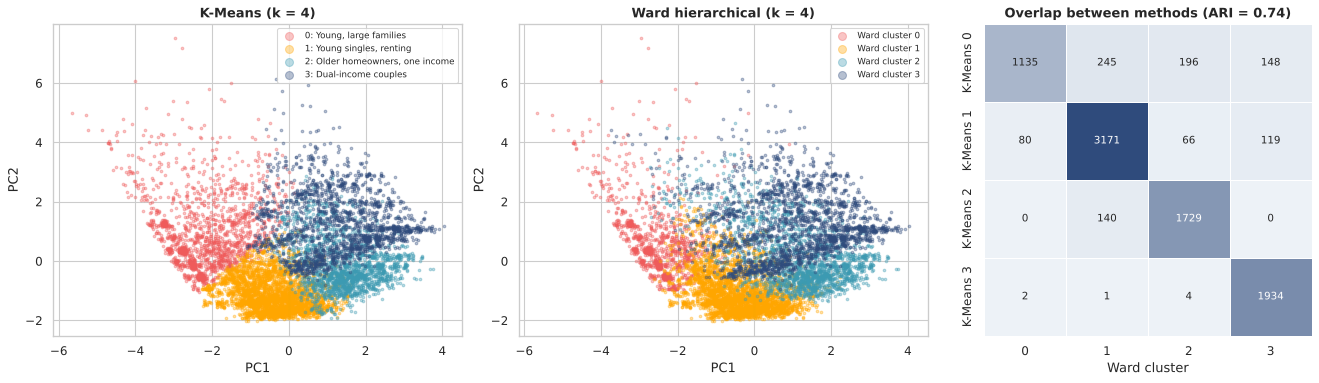

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1, 0.8]})

for ax, col, title in zip(axes[:2], ["KMEANS", "WARD"], ["K-Means (k = 4)", "Ward hierarchical (k = 4)"]):
    for c in range(K):
        m = data[col].values == c
        ax.scatter(pc[m, 0] + jitter[m, 0], pc[m, 1] + jitter[m, 1], s=6, alpha=0.35,
                   color=CLUSTER_COLOURS[c], label=f"{c}: {KM_NAMES[c]}" if col == "KMEANS" else f"Ward cluster {c}")
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(fontsize=8, markerscale=3)

sns.heatmap(agree.set_axis([f"K-Means {c}" for c in range(K)]), annot=True, fmt="d", cmap=SEQ,
            linewidths=0.5, linecolor="white", cbar=False, ax=axes[2])
axes[2].set_ylabel("")
axes[2].set_title(f"Overlap between methods (ARI = {ari:.2f})")

plt.tight_layout()
plt.show()

## **15. Phase 2 Conclusion**

# **PHASE 3**

## **16. Note on Time Series Analysis (Module 3)**

In [ ]:
import statsmodels.stats.api as sms
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
date_like = [c for c in income_raw.columns
             if any(k in c.upper() for k in ["DATE", "TIME", "YEAR", "MONTH", "DAY", "PERIOD"])]

print("Columns that look like a date or time:", date_like if date_like else "none")
print("Columns pandas could parse as datetime:",
      [c for c in income_raw.columns if pd.api.types.is_datetime64_any_dtype(income_raw[c])] or "none")
print()
print("Every column and its type:")
print(income_raw.dtypes.rename_axis(None).to_string())

Columns that look like a date or time: none
Columns pandas could parse as datetime: none

Every column and its type:
INCOME            str
SEX               str
MARITAL.STATUS    str
AGE               str
EDUCATION         str
OCCUPATION        str
AREA              str
DUAL.INCOMES      str
HOUSEHOLD.SIZE    str
UNDER18           str
HOUSEHOLDER       str
HOME.TYPE         str
ETHNIC.CLASS      str
LANGUAGE          str


In [ ]:
cohort = (data.groupby("AGE_BAND", observed=True)
              .agg(median_income=("INCOME_K", "median"),
                   owns_home_pct=("OWNS_HOME", lambda s: s.mean() * 100),
                   dual_income_pct=("DUAL", lambda s: s.mean() * 100),
                   households=("INCOME_K", "size"))
              .round(1))
cohort

,median_income,owns_home_pct,dual_income_pct,households
AGE_BAND,,,,
14-17,5.0,2.5,0.8,855
18-24,17.5,9.2,9.9,2129
25-34,27.5,26.5,32.5,2249
35-44,45.0,54.6,42.8,1615
45-54,45.0,69.7,43.6,922
55-64,45.0,77.2,23.3,640
65+,27.5,75.0,2.9,560


### Plot 23 - Pseudo-cohort view across age bands

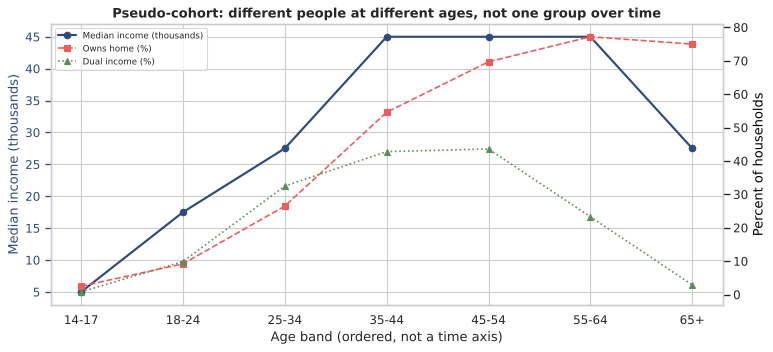

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.6))

ax.plot(cohort.index.astype(str), cohort["median_income"], marker="o", color=BLUE,
        linewidth=2, label="Median income (thousands)")
ax.set_ylabel("Median income (thousands)", color=BLUE)
ax.set_xlabel("Age band (ordered, not a time axis)")
ax.tick_params(axis="y", colors=BLUE)
ax.set_title("Pseudo-cohort: different people at different ages, not one group over time")

twin = ax.twinx()
twin.plot(cohort.index.astype(str), cohort["owns_home_pct"], marker="s", color=RED,
          linestyle="--", label="Owns home (%)")
twin.plot(cohort.index.astype(str), cohort["dual_income_pct"], marker="^", color=GREEN,
          linestyle=":", label="Dual income (%)")
twin.set_ylabel("Percent of households", color="black")
twin.grid(False)

lines = ax.get_lines() + twin.get_lines()
ax.legend(lines, [l.get_label() for l in lines], fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()

## **17. Principal Component Analysis (Module 6)**

In [ ]:
print("Features entering PCA:", features)
print("Observations:", X.shape[0])
print()
print("Confirming the input is standardised:")
pd.DataFrame({"mean": X.mean(axis=0).round(10), "std": X.std(axis=0).round(4)}, index=features)

Features entering PCA: ['INCOME_K', 'AGE_YEARS', 'EDU_RANK', 'HH_SIZE', 'CHILDREN', 'OWNS_HOME', 'DUAL']
Observations: 8970

Confirming the input is standardised:


,mean,std
INCOME_K,0.0,1.0
AGE_YEARS,0.0,1.0
EDU_RANK,-0.0,1.0
HH_SIZE,0.0,1.0
CHILDREN,0.0,1.0
OWNS_HOME,-0.0,1.0
DUAL,-0.0,1.0


### 17.1 How much variance each component carries

In [ ]:
pca_full = PCA(random_state=23).fit(X)

variance = pd.DataFrame({
    "eigenvalue": pca_full.explained_variance_,
    "variance_%": pca_full.explained_variance_ratio_ * 100,
    "cumulative_%": np.cumsum(pca_full.explained_variance_ratio_) * 100,
}, index=[f"PC{i+1}" for i in range(len(features))]).round(2)
variance

,eigenvalue,variance_%,cumulative_%
PC1,2.50,35.64,35.64
PC2,1.73,24.74,60.39
PC3,0.88,12.53,72.91
PC4,0.70,9.96,82.87
PC5,0.51,7.25,90.13
PC6,0.40,5.67,95.80
PC7,0.29,4.20,100.00


### Plot 24 - Scree plot and cumulative variance

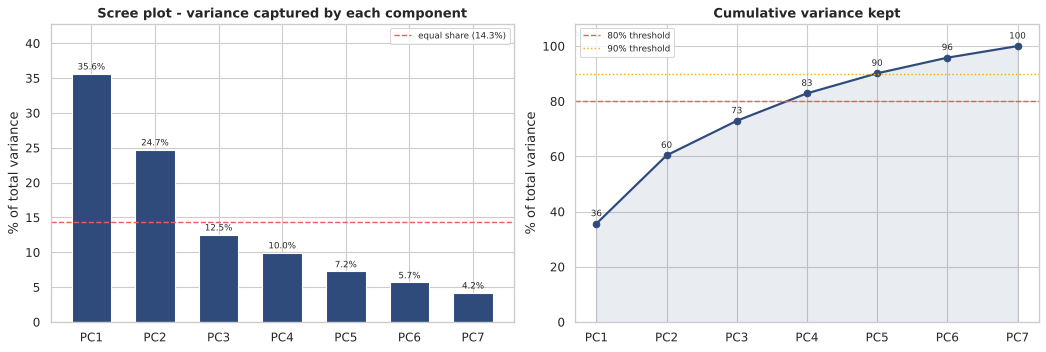

In [ ]:
pcs = variance.index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

bars = axes[0].bar(pcs, variance["variance_%"], color=BLUE, width=0.62)
axes[0].bar_label(bars, fmt="%.1f%%", padding=2, fontsize=8)
axes[0].axhline(100 / len(features), color=RED, linestyle="--", linewidth=1.3,
                label=f"equal share ({100/len(features):.1f}%)")
axes[0].set_title("Scree plot - variance captured by each component")
axes[0].set_ylabel("% of total variance")
axes[0].set_ylim(0, variance["variance_%"].max() * 1.2)
axes[0].legend(fontsize=8)

axes[1].plot(pcs, variance["cumulative_%"], marker="o", color=BLUE, linewidth=2)
axes[1].fill_between(pcs, variance["cumulative_%"], color=BLUE, alpha=0.1)
axes[1].axhline(80, color=RED, linestyle="--", linewidth=1.3, label="80% threshold")
axes[1].axhline(90, color=GOLD, linestyle=":", linewidth=1.3, label="90% threshold")
for x_, y_ in zip(pcs, variance["cumulative_%"]):
    axes[1].annotate(f"{y_:.0f}", (x_, y_), textcoords="offset points", xytext=(0, 7),
                     ha="center", fontsize=8)
axes[1].set_title("Cumulative variance kept")
axes[1].set_ylabel("% of total variance")
axes[1].set_ylim(0, 108)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 17.2 Choosing how many components to keep

In [ ]:
kaiser = int((variance["eigenvalue"] > 1).sum())
rule_80 = int((variance["cumulative_%"] < 80).sum() + 1)
rule_90 = int((variance["cumulative_%"] < 90).sum() + 1)

drops = variance["variance_%"].diff().abs()
elbow = int(drops.values[1:].argmax() + 1)

pd.DataFrame({
    "rule": ["Kaiser (eigenvalue > 1)", "Keep 80% of variance",
             "Keep 90% of variance", "Elbow in the scree plot"],
    "components": [kaiser, rule_80, rule_90, elbow],
})

,rule,components
0,Kaiser (eigenvalue > 1),2
1,Keep 80% of variance,4
2,Keep 90% of variance,5
3,Elbow in the scree plot,2


In [ ]:
N_COMP = kaiser
print(f"Components kept: {N_COMP}")
print(f"Variance retained: {variance['cumulative_%'].iloc[N_COMP - 1]:.1f}%")
print(f"Variance discarded: {100 - variance['cumulative_%'].iloc[N_COMP - 1]:.1f}%")
print(f"Dimensions reduced: {len(features)} -> {N_COMP}")

Components kept: 2
Variance retained: 60.4%
Variance discarded: 39.6%
Dimensions reduced: 7 -> 2


### 17.3 What the components mean

In [ ]:
loadings = pd.DataFrame(
    pca_full.components_[:N_COMP].T,
    index=features,
    columns=[f"PC{i+1}" for i in range(N_COMP)],
).round(3)
loadings

,PC1,PC2
INCOME_K,0.427,0.314
AGE_YEARS,0.451,0.010
EDU_RANK,0.436,-0.021
HH_SIZE,-0.304,0.578
CHILDREN,-0.306,0.564
OWNS_HOME,0.431,0.297
DUAL,0.228,0.401


### Plot 25 - Loadings heatmap and the PC1-PC2 biplot

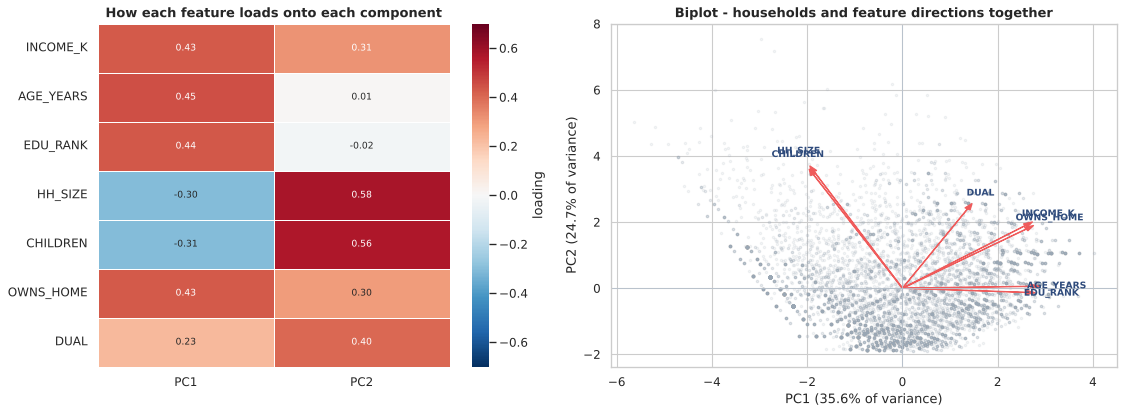

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4), gridspec_kw={"width_ratios": [1, 1.15]})

sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.7, vmax=0.7,
            linewidths=0.6, linecolor="white", annot_kws={"size": 8.5}, ax=axes[0],
            cbar_kws={"label": "loading"})
axes[0].set_title("How each feature loads onto each component")

pc2 = PCA(n_components=2, random_state=23)
scores = pc2.fit_transform(X)

axes[1].scatter(scores[:, 0], scores[:, 1], s=5, alpha=0.12, color="#9AA7B4")

scale = np.abs(scores[:, :2]).max() * 0.85
for i, f in enumerate(features):
    vx, vy = pc2.components_[0, i] * scale, pc2.components_[1, i] * scale
    axes[1].arrow(0, 0, vx, vy, color=RED, width=0.012, head_width=0.13, length_includes_head=True)
    axes[1].text(vx * 1.12, vy * 1.12, f, color=BLUE, fontsize=8.5, fontweight="bold",
                 ha="center", va="center")

axes[1].axhline(0, color="#B7C1CC", linewidth=0.8)
axes[1].axvline(0, color="#B7C1CC", linewidth=0.8)
axes[1].set_title("Biplot - households and feature directions together")
axes[1].set_xlabel(f"PC1 ({variance['variance_%'].iloc[0]:.1f}% of variance)")
axes[1].set_ylabel(f"PC2 ({variance['variance_%'].iloc[1]:.1f}% of variance)")

plt.tight_layout()
plt.show()

In [ ]:
for i in range(N_COMP):
    col = f"PC{i+1}"
    top = loadings[col].abs().sort_values(ascending=False).head(3).index.tolist()
    print(f"{col} ({variance['variance_%'].iloc[i]:.1f}% of variance) driven most by:")
    for f in top:
        v = loadings.loc[f, col]
        print(f"   {f:<12} {v:+.3f}  ({'raises' if v > 0 else 'lowers'} the score)")
    print()

PC1 (35.6% of variance) driven most by:
   AGE_YEARS    +0.451  (raises the score)
   EDU_RANK     +0.436  (raises the score)
   OWNS_HOME    +0.431  (raises the score)

PC2 (24.7% of variance) driven most by:
   HH_SIZE      +0.578  (raises the score)
   CHILDREN     +0.564  (raises the score)
   DUAL         +0.401  (raises the score)



### 17.4 How much is lost by dropping components

In [ ]:
recon_error = []
for k in range(1, len(features) + 1):
    p = PCA(n_components=k, random_state=23).fit(X)
    rebuilt = p.inverse_transform(p.transform(X))
    recon_error.append({
        "components": k,
        "variance_kept_%": round(p.explained_variance_ratio_.sum() * 100, 1),
        "mean_squared_error": round(float(np.mean((X - rebuilt) ** 2)), 4),
    })

recon = pd.DataFrame(recon_error).set_index("components")
recon

,variance_kept_%,mean_squared_error
components,,
1,35.6,0.6436
2,60.4,0.3961
3,72.9,0.2709
4,82.9,0.1713
5,90.1,0.0987
6,95.8,0.0420
7,100.0,0.0000


### Plot 26 - Reconstruction error against components kept

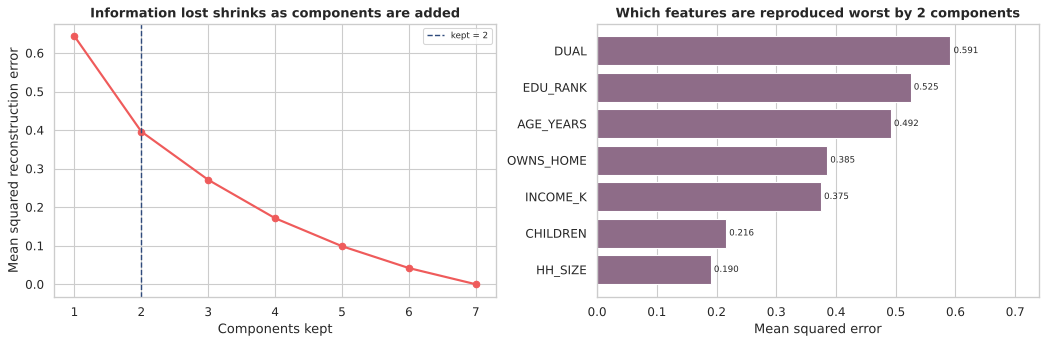

In [ ]:
p_keep = PCA(n_components=N_COMP, random_state=23).fit(X)
rebuilt = p_keep.inverse_transform(p_keep.transform(X))
per_feature = pd.Series(np.mean((X - rebuilt) ** 2, axis=0), index=features).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

axes[0].plot(recon.index, recon["mean_squared_error"], marker="o", color=RED, linewidth=2)
axes[0].axvline(N_COMP, color=BLUE, linestyle="--", linewidth=1.3, label=f"kept = {N_COMP}")
axes[0].set_title("Information lost shrinks as components are added")
axes[0].set_xlabel("Components kept")
axes[0].set_ylabel("Mean squared reconstruction error")
axes[0].legend(fontsize=8)

fbars = axes[1].barh(per_feature.index, per_feature.values, color=PURPLE)
axes[1].bar_label(fbars, fmt="%.3f", padding=3, fontsize=8)
axes[1].set_title(f"Which features are reproduced worst by {N_COMP} components")
axes[1].set_xlabel("Mean squared error")
axes[1].set_xlim(0, per_feature.max() * 1.25)
axes[1].grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

## **18. Simple Linear Regression (Module 7)**

### 18.1 Choosing the predictor

In [ ]:
candidates = ["EDU_RANK", "AGE_YEARS", "OWNS_HOME", "DUAL", "HH_SIZE", "CHILDREN", "AREA_YEARS"]

ranking = []
for c in candidates:
    sub = data[[c, "INCOME_K"]].dropna()
    r, p = stats.pearsonr(sub[c], sub["INCOME_K"])
    ranking.append({"predictor": c, "pearson_r": round(r, 3),
                    "r_squared_alone": round(r ** 2, 3),
                    "p_value": f"{p:.2e}", "n": len(sub)})

ranking = pd.DataFrame(ranking).sort_values("r_squared_alone", ascending=False).reset_index(drop=True)
ranking

,predictor,pearson_r,r_squared_alone,p_value,n
0,OWNS_HOME,0.473,0.224,0.00e+00,8970
1,EDU_RANK,0.430,0.185,0.00e+00,8970
2,DUAL,0.353,0.124,3.12e-261,8970
3,AGE_YEARS,0.314,0.099,4.62e-205,8970
4,AREA_YEARS,0.087,0.008,4.20e-15,8061
5,CHILDREN,-0.061,0.004,7.88e-09,8970
6,HH_SIZE,-0.020,0.000,6.22e-02,8970


In [ ]:
binary = [c for c in candidates if data[c].dropna().nunique() <= 2]
print("Excluded as binary:", binary)

eligible = ranking[~ranking["predictor"].isin(binary)].reset_index(drop=True)
PREDICTOR = eligible.loc[0, "predictor"]

print(f"Predictor chosen: {PREDICTOR} ({data[PREDICTOR].nunique()} distinct levels)")
print(f"It alone explains {eligible.loc[0, 'r_squared_alone'] * 100:.1f}% of the variation in income")
eligible

Excluded as binary: ['OWNS_HOME', 'DUAL']
Predictor chosen: EDU_RANK (6 distinct levels)
It alone explains 18.5% of the variation in income


,predictor,pearson_r,r_squared_alone,p_value,n
0,EDU_RANK,0.430,0.185,0.00e+00,8970
1,AGE_YEARS,0.314,0.099,4.62e-205,8970
2,AREA_YEARS,0.087,0.008,4.20e-15,8061
3,CHILDREN,-0.061,0.004,7.88e-09,8970
4,HH_SIZE,-0.020,0.000,6.22e-02,8970


### 18.2 Fitting the model

In [ ]:
reg_data = data[[PREDICTOR, "INCOME_K"]].dropna().rename(columns={PREDICTOR: "x", "INCOME_K": "y"})

slr = smf.ols("y ~ x", data=reg_data).fit()
print(slr.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.185
Model:                            OLS   Adj. R-squared:                  0.185
Method:                 Least Squares   F-statistic:                     2032.
Date:                Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:38:20   Log-Likelihood:                -40868.
No. Observations:                8970   AIC:                         8.174e+04
Df Residuals:                    8968   BIC:                         8.176e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.4040      0.794      0.509      0.6

In [ ]:
b0, b1 = slr.params["Intercept"], slr.params["x"]

print(f"Fitted line:  INCOME_K = {b0:.3f} + {b1:.3f} x {PREDICTOR}")
print()
print(f"Slope       = {b1:.3f}  (income changes by {b1:.3f} thousand per 1-unit rise in {PREDICTOR})")
print(f"Intercept   = {b0:.3f}  (predicted income when {PREDICTOR} = 0)")
print(f"R-squared   = {slr.rsquared:.4f}  ({slr.rsquared * 100:.1f}% of variation explained)")
print(f"Slope p-value = {slr.pvalues['x']:.3e}")
print(f"95% CI for slope: [{slr.conf_int().loc['x', 0]:.3f}, {slr.conf_int().loc['x', 1]:.3f}]")

Fitted line:  INCOME_K = 0.404 + 8.880 x EDU_RANK

Slope       = 8.880  (income changes by 8.880 thousand per 1-unit rise in EDU_RANK)
Intercept   = 0.404  (predicted income when EDU_RANK = 0)
R-squared   = 0.1847  (18.5% of variation explained)
Slope p-value = 0.000e+00
95% CI for slope: [8.494, 9.266]


### Plot 27 - The fitted line

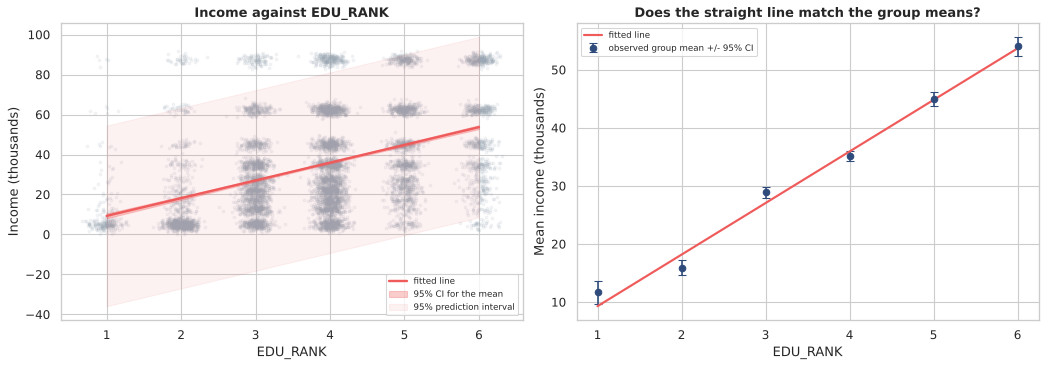

In [ ]:
rng3 = np.random.default_rng(23)
jx = reg_data["x"] + rng3.normal(0, 0.11, len(reg_data))
jy = reg_data["y"] + rng3.normal(0, 1.6, len(reg_data))

grid = pd.DataFrame({"x": np.linspace(reg_data["x"].min(), reg_data["x"].max(), 120)})
pred = slr.get_prediction(grid).summary_frame(alpha=0.05)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

axes[0].scatter(jx, jy, s=6, alpha=0.1, color="#9AA7B4")
axes[0].plot(grid["x"], pred["mean"], color=RED, linewidth=2.2, label="fitted line")
axes[0].fill_between(grid["x"], pred["mean_ci_lower"], pred["mean_ci_upper"],
                     color=RED, alpha=0.3, label="95% CI for the mean")
axes[0].fill_between(grid["x"], pred["obs_ci_lower"], pred["obs_ci_upper"],
                     color=RED, alpha=0.08, label="95% prediction interval")
axes[0].set_title(f"Income against {PREDICTOR}")
axes[0].set_xlabel(PREDICTOR)
axes[0].set_ylabel("Income (thousands)")
axes[0].legend(fontsize=8)

group = reg_data.groupby("x")["y"].agg(["mean", "sem", "size"])
axes[1].errorbar(group.index, group["mean"], yerr=1.96 * group["sem"], fmt="o",
                 color=BLUE, capsize=4, markersize=6, label="observed group mean +/- 95% CI")
axes[1].plot(grid["x"], pred["mean"], color=RED, linewidth=2, label="fitted line")
axes[1].set_title("Does the straight line match the group means?")
axes[1].set_xlabel(PREDICTOR)
axes[1].set_ylabel("Mean income (thousands)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 18.3 Checking the assumptions

In [ ]:
fitted, resid = slr.fittedvalues, slr.resid
std_resid = resid / resid.std()

bp = sms.het_breuschpagan(resid, slr.model.exog)
dw = sms.durbin_watson(resid)
shapiro_p = stats.shapiro(resid.sample(min(5000, len(resid)), random_state=23))[1]

pd.DataFrame({
    "assumption": ["Constant variance (Breusch-Pagan)", "Independence (Durbin-Watson)",
                   "Normal residuals (Shapiro-Wilk)"],
    "statistic": [round(bp[0], 2), round(dw, 3), "-"],
    "p_value": [f"{bp[1]:.3e}", "-", f"{shapiro_p:.3e}"],
    "reading": [
        "violated" if bp[1] < 0.05 else "satisfied",
        "satisfied" if 1.5 < dw < 2.5 else "possible autocorrelation",
        "violated" if shapiro_p < 0.05 else "satisfied",
    ],
})

,assumption,statistic,p_value,reading
0,Constant variance (Breusch-Pagan),123.07,1.347e-28,violated
1,Independence (Durbin-Watson),1.568,-,satisfied
2,Normal residuals (Shapiro-Wilk),-,4.168e-37,violated


### Plot 28 - Residual diagnostics

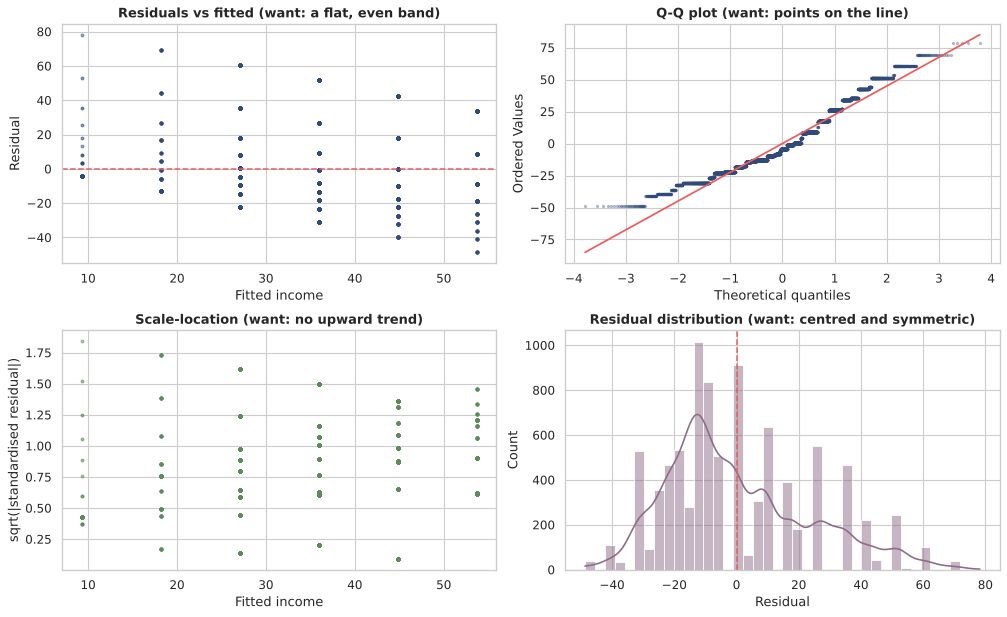

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].scatter(fitted, resid, s=6, alpha=0.12, color=BLUE)
axes[0, 0].axhline(0, color=RED, linestyle="--", linewidth=1.4)
axes[0, 0].set_title("Residuals vs fitted (want: a flat, even band)")
axes[0, 0].set_xlabel("Fitted income")
axes[0, 0].set_ylabel("Residual")

stats.probplot(resid, dist="norm", plot=axes[0, 1])
axes[0, 1].get_lines()[0].set(marker="o", markersize=2, alpha=0.3, color=BLUE)
axes[0, 1].get_lines()[1].set(color=RED, linewidth=1.6)
axes[0, 1].set_title("Q-Q plot (want: points on the line)")

axes[1, 0].scatter(fitted, np.sqrt(np.abs(std_resid)), s=6, alpha=0.12, color=GREEN)
axes[1, 0].set_title("Scale-location (want: no upward trend)")
axes[1, 0].set_xlabel("Fitted income")
axes[1, 0].set_ylabel("sqrt(|standardised residual|)")

sns.histplot(resid, bins=40, kde=True, color=PURPLE, edgecolor="white", ax=axes[1, 1])
axes[1, 1].axvline(0, color=RED, linestyle="--", linewidth=1.4)
axes[1, 1].set_title("Residual distribution (want: centred and symmetric)")
axes[1, 1].set_xlabel("Residual")

plt.tight_layout()
plt.show()

### 18.4 Does it predict on unseen data?

In [ ]:
train, test = train_test_split(reg_data, test_size=0.25, random_state=23)

model_train = smf.ols("y ~ x", data=train).fit()
pred_test = model_train.predict(test)

rmse = float(np.sqrt(mean_squared_error(test["y"], pred_test)))
mae = float(mean_absolute_error(test["y"], pred_test))
r2_test = float(r2_score(test["y"], pred_test))
baseline = float(np.sqrt(mean_squared_error(test["y"], np.full(len(test), train["y"].mean()))))

pd.DataFrame({
    "metric": ["Train rows", "Test rows", "R-squared (train)", "R-squared (test)",
               "RMSE (thousands)", "MAE (thousands)",
               "RMSE if always predicting the mean", "Improvement over the mean"],
    "value": [len(train), len(test), round(model_train.rsquared, 4), round(r2_test, 4),
              round(rmse, 2), round(mae, 2), round(baseline, 2),
              f"{(baseline - rmse) / baseline * 100:.1f}%"],
})

,metric,value
0,Train rows,6727
1,Test rows,2243
2,R-squared (train),0.1818
3,R-squared (test),0.1932
4,RMSE (thousands),22.77
5,MAE (thousands),18.28
6,RMSE if always predicting the mean,25.36
7,Improvement over the mean,10.2%


### 18.5 Regression on the first principal component

In [ ]:
pc_data = pd.DataFrame({"x": scores[:, 0], "y": data["INCOME_K"].values}).dropna()
slr_pc = smf.ols("y ~ x", data=pc_data).fit()

comparison = pd.DataFrame({
    "model": [f"Income ~ {PREDICTOR} (raw feature)", "Income ~ PC1 (PCA component)"],
    "r_squared": [round(slr.rsquared, 4), round(slr_pc.rsquared, 4)],
    "slope": [round(b1, 3), round(slr_pc.params["x"], 3)],
    "residual_std_error": [round(np.sqrt(slr.mse_resid), 2), round(np.sqrt(slr_pc.mse_resid), 2)],
    "AIC": [round(slr.aic, 1), round(slr_pc.aic, 1)],
})
comparison

,model,r_squared,slope,residual_std_error,AIC
0,Income ~ EDU_RANK (raw feature),0.1847,8.880,23.04,81740.8
1,Income ~ PC1 (PCA component),0.4547,10.893,18.84,78132.5


### Plot 29 - Raw predictor against PC1 as predictor

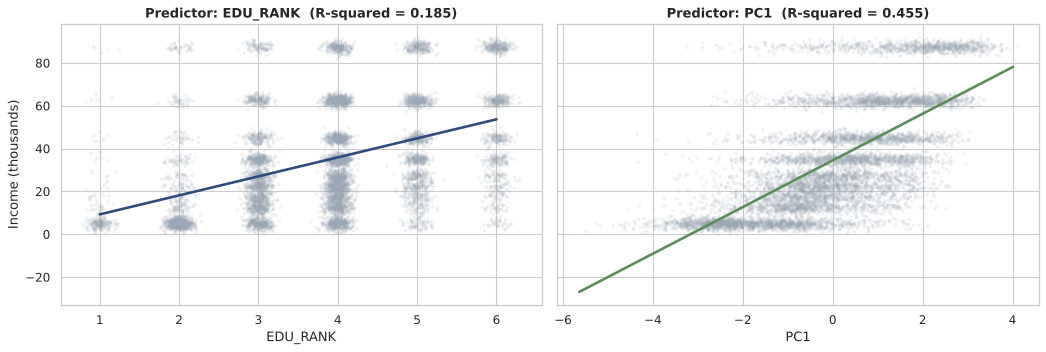

Better single predictor: PC1
R-squared gain from using PC1: +27.00 percentage points


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), sharey=True)

for ax, (xv, yv, model, title, colour) in zip(axes, [
        (reg_data["x"], reg_data["y"], slr, f"Predictor: {PREDICTOR}", BLUE),
        (pc_data["x"], pc_data["y"], slr_pc, "Predictor: PC1", GREEN)]):
    jig = rng3.normal(0, 0.09, len(xv)) if xv.std() < 3 else 0
    ax.scatter(xv + jig, yv + rng3.normal(0, 1.6, len(yv)), s=5, alpha=0.1, color="#9AA7B4")
    line_x = np.linspace(xv.min(), xv.max(), 100)
    ax.plot(line_x, model.params["Intercept"] + model.params["x"] * line_x,
            color=colour, linewidth=2.4)
    ax.set_title(f"{title}  (R-squared = {model.rsquared:.3f})")
    ax.set_xlabel(title.split(": ")[1])

axes[0].set_ylabel("Income (thousands)")
plt.tight_layout()
plt.show()

better = "PC1" if slr_pc.rsquared > slr.rsquared else PREDICTOR
print(f"Better single predictor: {better}")
print(f"R-squared gain from using PC1: {(slr_pc.rsquared - slr.rsquared) * 100:+.2f} percentage points")

## **19. Final Conclusion (Modules 2 to 7)**

**Getting the data usable (Module 2)**

1. Not a single column came as numbers. Income was stored as ranges, family size as words like "Three". All of it had to be converted before I could do anything.
2. I caught one bug that mattered. Pandas reads the word "None" in `UNDER18` as a missing value, so 5,724 real answers would have quietly disappeared. Reading the file differently fixed it.
3. Three real problems in the data: a spelling mistake in `EDUCATION`, 93 rows where marital status contradicted the dual income column, and 23 records that were simply impossible, like 14-year-olds listed as retired.

**What the data actually showed (Modules 3 and 4)**

4. Income has two peaks instead of one. The big under-10K group turned out to be students living at home, not low earners. I only saw this after putting income against age. Looking at income alone would have told me the wrong story.
5. Time series doesn't work on this data. There's no date column anywhere, so I used age bands as a rough stand-in and said clearly why it isn't the same thing.
6. Nothing follows a normal distribution, so I used rank-based methods instead of assuming normality.
7. Income moves with home ownership, education and age. It barely moves with household size or ethnicity.

**What the models found (Modules 5, 6, 7)**

8. K-Means and Ward clustering both found four household groups and mostly agreed on who belonged where. Two different methods agreeing makes the result more believable.
9. PCA separated the features into two groups: one about life stage (income, age, education, home ownership) and one about family size (household size, children). This is the same split clustering found, reached through completely different maths.
10. Education predicts income best out of the single variables. The relationship is clear and in the direction you'd expect. PC1 predicts a bit better but is much harder to explain to someone.
11. The residual tests fail, and I've left that in rather than hiding it. The reason is that income only has nine possible values, so the residuals come out in stripes. The effect itself is still reliable; the p-values are rough.

**Limitations**

- Every income and age number comes from the middle of a band, so they're estimates and not actual measurements.
- `ETHNIC_CLASS` and `LANGUAGE` are almost all one category, so comparing groups within them wouldn't mean much.
- Everything here is a pattern in one survey. None of it proves cause and effect.